HC 246脑区平均 INT 与 MDD 246脑区平均 INT 差异

=== 协方差分析 (ANCOVA) 结果 ===
             sum_sq     df          F    PR(>F)
C(Group)   0.466929    1.0   5.550273  0.018831
C(sex)     0.055820    1.0   0.663524  0.415674
age        0.036517    1.0   0.434073  0.510275
mean_fd    1.231027    1.0  14.632912  0.000146
Residual  45.849351  545.0        NaN       NaN

控制年龄、性别和头动(mean_fd)后，组间差异的真实 P 值: 1.883101e-02


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/1685985971.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/1685985971.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


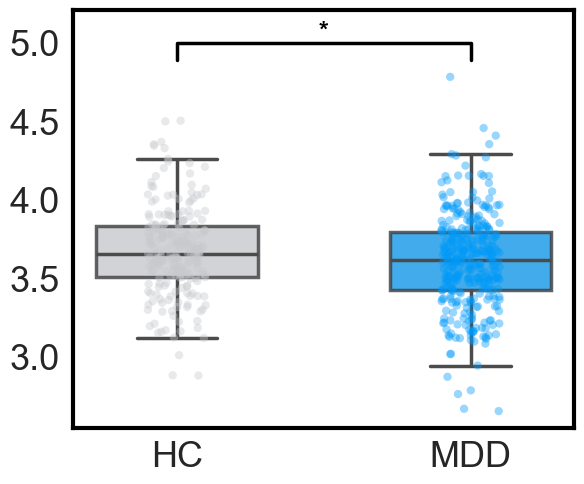

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols

# ==========================================
# 1. 读取数据与合并
# ==========================================
df_s1 = pd.read_csv(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/HC_mean_INT_agesex_FD.csv'
)
df_s2 = pd.read_csv(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/MDD_mean_INT_agesex_FD.csv'
)

df_s1['Group'] = 'HC'
df_s2['Group'] = 'MDD'

df = pd.concat([df_s1, df_s2], ignore_index=True)
df = df[['Group', 'age', 'sex', 'mean_INT', 'mean_fd']].dropna()

# ==========================================
# 2. 广义线性模型 (GLM) / 协方差分析 (ANCOVA)
# ==========================================
formula = 'mean_INT ~ C(Group) + age + C(sex) + mean_fd'
model = ols(formula, data=df).fit()

anova_table = sm.stats.anova_lm(model, typ=2)
print('=== 协方差分析 (ANCOVA) 结果 ===')
print(anova_table)

target_param = 'C(Group)[T.MDD]'
p_val = model.pvalues.get(target_param, np.nan)
t_val = model.tvalues.get(target_param, np.nan)
print(f'\n控制年龄、性别和头动(mean_fd)后，组间差异的真实 P 值: {p_val:.6e}')

# ==========================================
# 3. 绘制并动态智能标注显著性的箱体图
# ==========================================
plt.figure(figsize=(6, 5))

# 设置画板背景为白色
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 自定义颜色字典：HC 为 #42B8B1，MDD 为 #6AB4DC
palette_colors = {'HC': '#C6C9CD', 'MDD': '#009afa'}

# 绘制箱体图（通过 linewidth 调粗箱体线条）
ax = sns.boxplot(
    x='Group',
    y='mean_INT',
    data=df,
    order=['HC', 'MDD'],
    palette=palette_colors,
    width=0.55,
    showfliers=False,
    saturation=.85,
    linewidth=2.5,  # 调粗箱体线条
    boxprops={'alpha': 0.8,'edgecolor': '#3C3B3D'},
    # 是否保留箱体的线条
)

# 绘制散点图（通过 size 调大散点圆的大小）
sns.stripplot(
    x='Group',
    y='mean_INT',
    data=df,
    order=['HC', 'MDD'],
    #color='black',
    palette=palette_colors,
    alpha=0.4,
    size=6,  # 调大散点圆的大小
    jitter=True,
)

# 设置四周边框（上下左右轴）为黑色，线条加粗
for spine in ax.spines.values():
  spine.set_edgecolor('black')
  spine.set_linewidth(3)
  spine.set_visible(True)

# 计算画线位置
y_max = df['mean_INT'].max()
y_range = df['mean_INT'].max() - df['mean_INT'].min()
h = y_range * 0.05
line_y = y_max + h

# 如果 p_val < 0.05，则绘制连线和星号
if p_val < 0.05:
  x1, x2 = 0, 1
  plt.plot(
      [x1, x1, x2, x2],
      [line_y, line_y + h, line_y + h, line_y],
      lw=2.5,
      c='black',
  )

  if p_val < 0.001:
    stars = '***'
  elif p_val < 0.01:
    stars = '**'
  else:
    stars = '*'

  plt.text(
      (x1 + x2) * 0.5,
      line_y + h,
      stars,
      ha='center',
      va='bottom',
      color='black',
      fontsize=18,
      fontweight='bold',
  )
plt.xticks(fontsize=26)
plt.yticks(fontsize=26)
# 留出顶部空间
plt.ylim(df['mean_INT'].min() - y_range * 0.05, line_y + h * 3)

# 图表标签
plt.ylabel('', fontsize=12)
plt.xlabel('', fontsize=12)
plt.tight_layout()

# 保存图片
out_fig = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/Fig_HC_MDD_meanINT2.png'
plt.savefig(out_fig, dpi=300, bbox_inches='tight')



HC 8网络INT 与 MDD 8网络INT 差异
第一种风格

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

'''
    HC MDD 8个网络进行比较 INT
    - 统计：使用多元回归 (ANCOVA) 严格控制年龄、性别和头动(mean_fd)，计算显著性
    - 绘图：计算残差以展示去混淆后的数据分布
'''
# ================== 1. 读取数据 ==================
# 确保你的 CSV 文件中包含 'mean_fd' 这一列
hc_df = pd.read_csv(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/HC_INT20_7net_agesex_FD.csv'
)
mdd_df = pd.read_csv(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/MDD_INT20_7net_agesex.csv'
)

# 打标签并合并
hc_df['Group'] = 'HC'
mdd_df['Group'] = 'MDD'
combined_df = pd.concat([hc_df, mdd_df], axis=0).reset_index(drop=True)

# 定义内部原始变量名
networks = [
    'subcortical',
    'Visual',
    'Somatomotor',
    'Dorsal_Attention',
    'Ventral_Attention',
    'Limbic',
    'Frontoparietal',
    'Default',
]

# 定义用于显示在 X 轴上的好看的标签名称
network_labels = [
    'SC',
    'VIS',
    'SMN',
    'DAN',
    'VAN',
    'LIM',
    'FPN',
    'DMN',
]

covariates = ['age', 'sex', 'mean_fd']

print(f'总样本数: {len(combined_df)} (HC: {len(hc_df)}, MDD: {len(mdd_df)})')

# ================== 2. 严谨的统计检验 (多元回归 ANCOVA) ==================
results = []

for net in networks:
  # 回归公式，将 mean_fd 作为连续变量加入模型
  formula = (
      f"{net} ~ C(Group, Treatment(reference='HC')) + age + C(sex) + mean_fd"
  )

  # 拟合 OLS 模型
  model = smf.ols(formula, data=combined_df).fit()

  # 提取 MDD 组相较于 HC 组的主效应系数
  coef_name = "C(Group, Treatment(reference='HC'))[T.MDD]"
  t_stat = model.tvalues[coef_name]
  p_val = model.pvalues[coef_name]

  # 计算原始均值用于表格展示
  hc_raw_mean = combined_df[combined_df['Group'] == 'HC'][net].mean()
  mdd_raw_mean = combined_df[combined_df['Group'] == 'MDD'][net].mean()

  results.append({
      'Network': net,
      'HC_mean_raw': round(hc_raw_mean, 4),
      'MDD_mean_raw': round(mdd_raw_mean, 4),
      't': round(t_stat, 3),
      'p_raw': p_val,
  })

# 转换为 DataFrame 并进行 FDR 校正
from statsmodels.stats.multitest import fdrcorrection

result_df = pd.DataFrame(results)
_, p_fdr = fdrcorrection(result_df['p_raw'], alpha=0.05)
result_df['p_fdr'] = p_fdr
result_df['significant'] = result_df['p_fdr'] < 0.05

# 排序方便查看
result_df = result_df.sort_values('p_fdr')

print('\n=== 多元回归控制 Age/Sex/Mean_FD 后的组间差异 (ANCOVA) ===')
print(result_df)

# ================== 3. 画图数据准备 (回归年龄、性别、头动求残差) ==================
corrected_data = combined_df.copy()

for net in networks:
  mask = combined_df[[net] + covariates].notnull().all(axis=1)
  temp_df = combined_df[mask]

  # 使用包含 mean_fd 的公式来提取残差
  resid_formula = f'{net} ~ age + C(sex) + mean_fd'
  resid_model = smf.ols(resid_formula, data=temp_df).fit()

  # 将残差存回原数据框，加上原始均值保持量级
  corrected_data.loc[mask, net] = resid_model.resid + temp_df[net].mean()

# ================== 4. 绘图 (使用残差数据 + 多元回归的显著性P值) ==================
plt.figure(figsize=(16, 10))

# 设置画板背景为白色
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 自定义颜色方案
group_palette = {'HC': '#42B8B1', 'MDD': '#6AB4DC'}

# 转换数据格式以适配 seaborn
plot_data = corrected_data.melt(
    id_vars='Group',
    value_vars=networks,
    var_name='Network',
    value_name='INT',
)

# 绘制箱体图
ax = sns.boxplot(
    x='Network',
    y='INT',
    hue='Group',
    data=plot_data,
    order=networks,  # 确保顺序与原代码一致
    palette=group_palette,
    width=0.6,
    showfliers=False,
    linewidth=1.7,
    boxprops={'alpha': 0.8, 'edgecolor': '#3C3B3D'},
)

# 绘制散点图
sns.stripplot(
    x='Network',
    y='INT',
    hue='Group',
    data=plot_data,
    order=networks,  # 确保顺序与原代码一致
    dodge=True,
    alpha=0.4,
    jitter=True,
    size=5,
    palette=group_palette,
    legend=False,
)

# 设置四周边框（上下左右轴）为黑色，线条加粗
for spine in ax.spines.values():
  spine.set_edgecolor('black')
  spine.set_linewidth(1.7)
  spine.set_visible(True)

# 标注显著性 (根据第二步严谨算出的 result_df)
for i, net in enumerate(networks):
  p = result_df.loc[result_df['Network'] == net, 'p_fdr'].values[0]
  sig = (
      '***'
      if p < 0.001
      else '**' if p < 0.01 else '*' if p < 0.06 else 'n.s.'
  )

  # 找到最大值用于确定文字高度
  y_max = corrected_data[net].max()
  plt.text(i, y_max * 1.02, sig, ha='center', fontsize=18, fontweight='bold')

# 修复重复图例的问题
handles, labels = ax.get_legend_handles_labels()
plt.legend(
    handles[0:2],
    labels[0:2],
    title='',
    loc='upper right',
    fontsize=18,  # 调大图例文字大小
    markerscale=2,  # 调大图例中圆点/符号的相对大小
    frameon=False,
)

plt.ylabel('', fontsize=14)
plt.xlabel('', fontsize=14)

# 修改 X 轴刻度标签为用户指定的新名称
plt.xticks(
    ticks=range(len(networks)), labels=network_labels, fontsize=26
)
plt.yticks(fontsize=26)

# 为了防止星星被图表顶部边缘裁掉，稍微拉高 Y 轴上限
bottom, top = plt.ylim()
plt.ylim(bottom, top + (top - bottom) * 0.05)

plt.tight_layout()
plt.savefig(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/Fig_HCMDD_8NetINT_Diff.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

HC 8网络INT 与 MDD 8网络INT 差异
第二种风格

总样本数: 550 (HC: 215, MDD: 335)
             Network  HC_mean_raw  MDD_mean_raw      t     p_raw
0        subcortical       3.3402        3.2843 -2.254  0.024583
1             Visual       3.7729        3.6988 -2.600  0.009579
2        Somatomotor       3.7153        3.6446 -1.900  0.058024
3   Dorsal_Attention       3.8269        3.7581 -2.223  0.026657
4  Ventral_Attention       3.6758        3.5974 -2.213  0.027325
5             Limbic       3.4527        3.4278 -0.890  0.373870
6     Frontoparietal       3.8366        3.7743 -2.284  0.022744
7            Default       3.8141        3.7325 -2.852  0.004503
             Network  HC_mean_raw  MDD_mean_raw      t     p_raw     p_fdr  \
0        subcortical       3.3402        3.2843 -2.254  0.024583  0.036433   
1             Visual       3.7729        3.6988 -2.600  0.009579  0.036433   
2        Somatomotor       3.7153        3.6446 -1.900  0.058024  0.066313   
3   Dorsal_Attention       3.8269        3.7581 -2.223  0.026657  0.03643

/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_12248/902332506.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_12248/902332506.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_12248/902332506.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_12248/902332506.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated

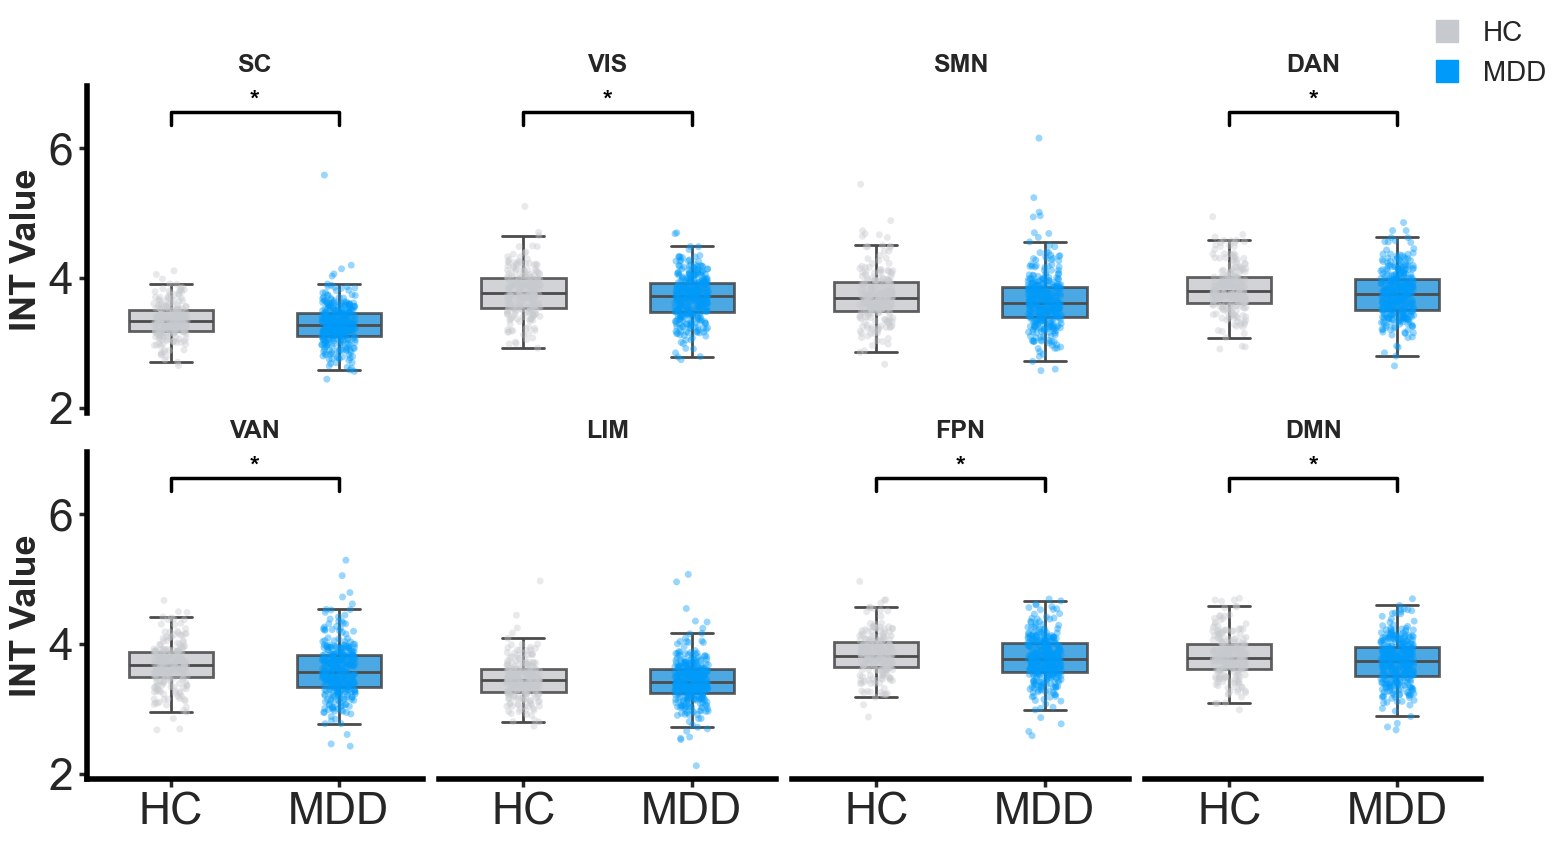


=== 绘图完成！图片已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/Fig_HCMDD_8NetINT_Diff_2x4.png ===
统计结果 CSV: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/ANCOVA_HC_MDD_8Networks_INT_Results.csv


In [9]:
import os
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import fdrcorrection

# ================== 1. 读取数据 ==================
base_dir = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest'

hc_df = pd.read_csv(os.path.join(base_dir, 'HC_INT20_7net_agesex_FD.csv'))
mdd_df = pd.read_csv(os.path.join(base_dir, 'MDD_INT20_7net_agesex.csv'))

hc_df['Group'] = 'HC'
mdd_df['Group'] = 'MDD'
combined_df = pd.concat([hc_df, mdd_df], axis=0).reset_index(drop=True)

networks = [
    'subcortical', 'Visual', 'Somatomotor', 'Dorsal_Attention',
    'Ventral_Attention', 'Limbic', 'Frontoparietal', 'Default'
]
network_labels = ['SC', 'VIS', 'SMN', 'DAN', 'VAN', 'LIM', 'FPN', 'DMN']
covariates = ['age', 'sex', 'mean_fd']

print(f'总样本数: {len(combined_df)} (HC: {len(hc_df)}, MDD: {len(mdd_df)})')

# ================== 2. 多元回归 ANCOVA ==================
results = []

for net in networks:
    formula = f"{net} ~ C(Group, Treatment(reference='HC')) + age + C(sex)"
    model = smf.ols(formula, data=combined_df).fit()

    coef_name = "C(Group, Treatment(reference='HC'))[T.MDD]"
    t_stat = model.tvalues[coef_name]
    p_val = model.pvalues[coef_name]

    hc_raw_mean = combined_df[combined_df['Group'] == 'HC'][net].mean()
    mdd_raw_mean = combined_df[combined_df['Group'] == 'MDD'][net].mean()

    results.append({
        'Network': net,
        'HC_mean_raw': round(hc_raw_mean, 4),
        'MDD_mean_raw': round(mdd_raw_mean, 4),
        't': round(t_stat, 3),
        'p_raw': p_val
    })

result_df = pd.DataFrame(results)
print(result_df)
_, p_fdr = fdrcorrection(result_df['p_raw'], alpha=0.05)
result_df['p_fdr'] = p_fdr
result_df['significant'] = result_df['p_fdr'] < 0.05

print(result_df,'\n=== 多元回归控制 Age/Sex 后的组间差异 (ANCOVA) ===')

# ================== 3. 保存统计结果 CSV（新增） ==================
out_csv = os.path.join(base_dir, 'ANCOVA_HC_MDD_8Networks_INT_Results.csv')
result_df.to_csv(out_csv, index=False, encoding='utf-8-sig', float_format='%.6f')
print(f'统计结果已保存至: {out_csv}')

# ================== 4. 绘图数据准备 ==================
corrected_data = combined_df.copy()

for net in networks:
    mask = combined_df[[net] + covariates].notnull().all(axis=1)
    temp_df = combined_df[mask]

    resid_formula = f'{net} ~ age + C(sex) '
    resid_model = smf.ols(resid_formula, data=temp_df).fit()
    corrected_data.loc[mask, net] = resid_model.resid + temp_df[net].mean()

all_vals = []
for net in networks:
    all_vals.extend(corrected_data[net].dropna().values)

global_y_min = min(all_vals)
global_y_max = max(all_vals)
global_y_range = global_y_max - global_y_min
h_global = global_y_range * 0.05

unified_ylim_top = global_y_max + h_global * 4
unified_ylim_bottom = global_y_min - global_y_range * 0.05
custom_yticks = [2, 4, 6]

# ================== 5. 绘图（2行4列） ==================
sns.set_theme(style='white', rc={
    'axes.facecolor': 'white',
    'figure.facecolor': 'white'
})
group_palette = {'HC': '#C6C9CD', 'MDD': '#009afa'}

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 9))
axes = axes.flatten()

for i, (net, label) in enumerate(zip(networks, network_labels)):
    ax = axes[i]
    df_net = corrected_data[['Group', net]].dropna().copy()
    df_net.rename(columns={net: 'INT'}, inplace=True)

    sns.boxplot(
        x='Group', y='INT', data=df_net, order=['HC', 'MDD'],
        palette=group_palette, width=0.5, showfliers=False,
        linewidth=2, boxprops={'alpha': 0.8, 'edgecolor': '#3C3B3D'},
        ax=ax
    )

    sns.stripplot(
        x='Group', y='INT', data=df_net, order=['HC', 'MDD'],
        dodge=False, alpha=0.4, jitter=True, size=5,
        palette=group_palette, legend=False, ax=ax
    )

    ax.set_xlim(-0.5, 1.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_title(label, fontsize=18, fontweight='bold', pad=10)
    ax.set_xlabel('')
    ax.set_ylim(unified_ylim_bottom, unified_ylim_top)
    ax.set_yticks(custom_yticks)

    # Y轴：仅第一列显示
    if i % 4 == 0:
        ax.spines['left'].set_color('black')
        ax.spines['left'].set_linewidth(4)
        ax.spines['left'].set_visible(True)
        ax.set_ylabel('INT Value', fontsize=26, fontweight='bold')
        ax.tick_params(axis='y', labelsize=32, left=True, width=2.5, length=6)
    else:
        ax.spines['left'].set_visible(False)
        ax.set_ylabel('')
        ax.tick_params(axis='y', left=False, labelleft=False)

    # X轴：仅第二行显示
    if i >= 4:
        ax.spines['bottom'].set_color('black')
        ax.spines['bottom'].set_linewidth(4)
        ax.spines['bottom'].set_visible(True)
        ax.set_xticklabels(['HC', 'MDD'], fontsize=32)
        ax.tick_params(axis='x', bottom=True, labelbottom=True, width=2.5, length=6)
    else:
        ax.spines['bottom'].set_visible(False)
        ax.set_xticklabels([])
        ax.tick_params(axis='x', bottom=False, labelbottom=False)

    # 显著性连线和星号
    p = result_df.loc[result_df['Network'] == net, 'p_fdr'].values[0]
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ' '
    line_y = global_y_max + h_global

    if sig != ' ':
        ax.plot(
            [0, 0, 1, 1],
            [line_y, line_y + h_global, line_y + h_global, line_y],
            lw=2.5, c='black'
        )
        ax.text(
            0.5, line_y + h_global, sig,
            ha='center', va='bottom', color='black',
            fontsize=18, fontweight='bold'
        )
    else:
        ax.text(
            0.5, line_y, sig,
            ha='center', va='bottom', color='black', fontsize=18
        )

# ================== 6. 图例与图片保存 ==================
hc_patch = mlines.Line2D(
    [], [], color='#C6C9CD', marker='s',
    linestyle='None', markersize=16, label='HC'
)
mdd_patch = mlines.Line2D(
    [], [], color='#009afa', marker='s',
    linestyle='None', markersize=16, label='MDD'
)

fig.legend(
    handles=[hc_patch, mdd_patch],
    loc='upper right', bbox_to_anchor=(0.95, 0.98),
    fontsize=20, frameon=False, ncol=1, handletextpad=0.3
)

plt.subplots_adjust(hspace=0.12, wspace=0.05)

out_fig = os.path.join(base_dir, 'Fig_HCMDD_8NetINT_Diff_2x4.png')
plt.savefig(out_fig, dpi=300, bbox_inches='tight')
plt.show()

print(f'\n=== 绘图完成！图片已保存至: {out_fig} ===')
print(f'统计结果 CSV: {out_csv}')

脑区水平：HC subtype1 subtype2 BNA246脑区mean INT 差异比较
箱体填充风格

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.conftest import matplotlib
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import seaborn as sns

matplotlib.use('Agg')
# =========================================================
# 1. 读取文件与数据合并
# =========================================================
base_dir = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step2_BN246mean_INT/'
# 注意：请确保以下读取的csv文件中都包含 'mean_fd' 列
df_hc = pd.read_csv(base_dir + 'HC_BN246_meanINT_agesex_FD.csv')
df_s1 = pd.read_csv(base_dir + 'subtype1_mean_INT_agesex_FD.csv')
df_s2 = pd.read_csv(base_dir + 'subtype2_mean_INT_agesex_FD.csv')

df_hc['group'] = 'HC'
df_s1['group'] = 'Subtype1'
df_s2['group'] = 'Subtype2'

df = pd.concat([df_hc, df_s1, df_s2], ignore_index=True)

# 【修改点 1】：在提取列时，加入 'mean_fd' 并去除缺失值
df = df[['group', 'age', 'sex', 'mean_INT', 'mean_fd']].dropna()

# =========================================================
# 2. ANCOVA 主效应模型构建
# =========================================================
# 【修改点 2】：将 mean_fd 添加到线性回归模型公式中
model = ols('mean_INT ~ C(group) + age + C(sex) + mean_fd', data=df).fit()

# 计算协方差分析表 (主效应) 并保存
anova_table = sm.stats.anova_lm(model, typ=2)
print('========== 协方差分析表 (ANCOVA 主效应) ==========')
print(anova_table)
anova_table.to_csv(
    base_dir + 'Diff_mean_INT_ANCOVA_MainEffect_covFD.csv'
)  # 更新文件名以示区别

# =========================================================
# 3. 事后检验分析 (Pairwise Comparisons) 与 FDR 校正
# =========================================
pairwise_results = []
# 这里的 contrast 不变，因为我们只关心 C(group) 的差异，其他协变量 (age, sex, mean_fd) 在对比时保持不变（互相抵消）
contrasts = {
    'HC_vs_Subtype1': "C(group)[T.Subtype1] = 0",
    'HC_vs_Subtype2': "C(group)[T.Subtype2] = 0",
    'Subtype1_vs_Subtype2': 'C(group)[T.Subtype1] - C(group)[T.Subtype2] = 0',
}

for comp_name, contrast_str in contrasts.items():
  t_test_res = model.t_test(contrast_str)
  p_val = (
      t_test_res.pvalue.item()
      if hasattr(t_test_res.pvalue, 'item')
      else float(t_test_res.pvalue)
  )
  t_val = (
      t_test_res.tvalue.item()
      if hasattr(t_test_res.tvalue, 'item')
      else float(t_test_res.tvalue)
  )
  pairwise_results.append(
      {'Comparison': comp_name, 't_value': t_val, 'p_uncorrected': p_val}
  )

pairwise_df = pd.DataFrame(pairwise_results)

# 对这 3 次两两比较进行 FDR 多重比较校正
_, p_fdr_pair, _, _ = multipletests(
    pairwise_df['p_uncorrected'], alpha=0.05, method='fdr_bh'
)
pairwise_df['p_FDR'] = p_fdr_pair


def get_stars(p):
  if p < 0.001:
    return '***'
  elif p < 0.01:
    return '**'
  elif p < 0.05:
    return '*'
  else:
    return 'ns'


pairwise_df['Significance'] = pairwise_df['p_FDR'].apply(get_stars)

# 保存事后检验详细结果
pairwise_df.to_csv(
    base_dir + 'Diff_mean_INT_ANCOVA_Pairwise_covFD.csv', index=False
)
print('\n========== 事后两两比较 (FDR 校正) ==========')
print(pairwise_df)


# =========================================================
# 4. 绘制并动态智能标注显著性的箱体图
# ==========================================
plt.figure(figsize=(8, 6))

# 【修改点】设置画板背景为白色，边框加粗
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 【修改点】自定义配色字典
custom_palette = {'HC': '#C6C9CD', 'Subtype1': '#B50A27', 'Subtype2': '#00478D'}

# 绘制箱体图
ax = sns.boxplot(
    x='group',
    y='mean_INT',
    data=df,
    order=['HC', 'Subtype1', 'Subtype2'],
    palette=custom_palette,
    width=0.5,
    showfliers=False,
    linewidth=1.7,
    boxprops={'alpha': 0.8, 'edgecolor': '#3C3B3D'}, # #3C3B3D
)
# groups_order = ['HC', 'Subtype1', 'Subtype2']
# # 【修复点】：使用 enumerate 提取索引 i，解决原代码中字符串相乘报错的问题
# for i, group_name in enumerate(groups_order):
#     group_color = '#3C3B3D'
#     group_color = custom_palette[group_name]
#     # boxplot 生成的线条包含 whiskers(须), caps(盖帽), medians(中位数线)
#     ax.lines[i*5 + 0].set_color(group_color)  # whisker 1
#     ax.lines[i*5 + 1].set_color(group_color)  # whisker 2
#     ax.lines[i*5 + 2].set_color(group_color)  # cap 1
#     ax.lines[i*5 + 3].set_color(group_color)  # cap 2
#     ax.lines[i*5 + 4].set_color(group_color)  # median linemedian line
# 绘制散点图
sns.stripplot(
    x='group',
    y='mean_INT',
    data=df,
    order=['HC', 'Subtype1', 'Subtype2'],
    palette=custom_palette,
    alpha=0.5,
    size=6,
    jitter=True,
)

# 设置四周边框（上下左右轴）为黑色，线条加粗
for spine in ax.spines.values():
  spine.set_edgecolor('black')
  spine.set_linewidth(1.7)
  spine.set_visible(True)

y_max = df['mean_INT'].max()
y_min = df['mean_INT'].min()
y_range = y_max - y_min

# 连线的动态高度步长和拐角小尾巴长度
step = 0.08 * y_range
h = 0.02 * y_range
current_y = y_max + 0.05 * y_range

# 提取 FDR 校正后的星号
star_hc_s1 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype1'][
    'Significance'
].values[0]
star_s1_s2 = pairwise_df[pairwise_df['Comparison'] == 'Subtype1_vs_Subtype2'][
    'Significance'
].values[0]
star_hc_s2 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype2'][
    'Significance'
].values[0]


def add_bracket(x1, x2, y, text_star):
  plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, color='black')
  plt.text(
      (x1 + x2) * 0.5,
      y + h + 0.01 * y_range,
      text_star,
      ha='center',
      va='bottom',
      color='black',
      fontsize=14,
      fontweight='bold',
  )

# 动态堆叠画线逻辑：只有显著的 ('ns' 以外) 才画线
if star_hc_s1 != 'ns':
  add_bracket(0, 1, current_y, star_hc_s1)
  current_y += step

if star_s1_s2 != 'ns':
  add_bracket(1, 2, current_y, star_s1_s2)
  current_y += step

if star_hc_s2 != 'ns':
  add_bracket(0, 2, current_y, star_hc_s2)
  current_y += step

# 自动调整 y 轴范围，为顶部的连线留出空间
plt.ylim(y_min - 0.05 * y_range, current_y + 0.1 * y_range)

# 图表标签与字体大小调整
plt.ylabel('', fontsize=14)
plt.xlabel('', fontsize=14)
plt.xticks(fontsize=26)
plt.yticks(fontsize=26)
plt.tight_layout()

# 保存并展示图片
img_save_path = base_dir + 'Fig_Diff_mean_INT_ANCOVA_Stars_covFD2.png'
plt.savefig(img_save_path, dpi=300, bbox_inches='tight')

========== 协方差分析表 (ANCOVA 主效应) ==========
             sum_sq     df           F        PR(>F)
C(group)  17.051099    2.0  158.478399  5.860989e-55
C(sex)     0.770725    1.0   14.326741  1.707489e-04
age        0.007340    1.0    0.136435  7.119948e-01
mean_fd    0.671172    1.0   12.476175  4.471835e-04
Residual  29.265181  544.0         NaN           NaN

========== 事后两两比较 (FDR 校正) ==========
             Comparison    t_value  p_uncorrected         p_FDR Significance
0        HC_vs_Subtype1   7.456515   3.527669e-13  3.527669e-13          ***
1        HC_vs_Subtype2 -11.332397   7.148603e-27  1.072290e-26          ***
2  Subtype1_vs_Subtype2  17.557825   5.227206e-55  1.568162e-54          ***


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/2199663136.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/2199663136.py:134: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


脑区水平：HC subtype1 subtype2 BNA246脑区mean INT 差异比较
箱体不填充风格

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.conftest import matplotlib
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import seaborn as sns

matplotlib.use('Agg')
# =========================================================
# 1. 读取文件与数据合并
# =========================================================
base_dir = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step2_BN246mean_INT/'
# 注意：请确保以下读取的csv文件中都包含 'mean_fd' 列
df_hc = pd.read_csv(base_dir + 'HC_BN246_meanINT_agesex_FD.csv')
df_s1 = pd.read_csv(base_dir + 'subtype1_mean_INT_agesex_FD.csv')
df_s2 = pd.read_csv(base_dir + 'subtype2_mean_INT_agesex_FD.csv')

df_hc['group'] = 'HC'
df_s1['group'] = 'Subtype1'
df_s2['group'] = 'Subtype2'

df = pd.concat([df_hc, df_s1, df_s2], ignore_index=True)

# 提取列时，加入 'mean_fd' 并去除缺失值
df = df[['group', 'age', 'sex', 'mean_INT', 'mean_fd']].dropna()

# =========================================================
# 2. ANCOVA 主效应模型构建
# =========================================================
model = ols('mean_INT ~ C(group) + age + C(sex) + mean_fd', data=df).fit()

# 计算协方差分析表 (主效应) 并保存
anova_table = sm.stats.anova_lm(model, typ=2)
print('========== 协方差分析表 (ANCOVA 主效应) ==========')
#print(anova_table)
anova_table.to_csv(
    base_dir + 'Diff_mean_INT_ANCOVA_MainEffect_covFD.csv'
)

# =========================================================
# 3. 事后检验分析 (Pairwise Comparisons) 与 FDR 校正
# =========================================
pairwise_results = []
contrasts = {
    'HC_vs_Subtype1': "C(group)[T.Subtype1] = 0",
    'HC_vs_Subtype2': "C(group)[T.Subtype2] = 0",
    'Subtype1_vs_Subtype2': 'C(group)[T.Subtype1] - C(group)[T.Subtype2] = 0',
}

for comp_name, contrast_str in contrasts.items():
  t_test_res = model.t_test(contrast_str)
  p_val = (
      t_test_res.pvalue.item()
      if hasattr(t_test_res.pvalue, 'item')
      else float(t_test_res.pvalue)
  )
  t_val = (
      t_test_res.tvalue.item()
      if hasattr(t_test_res.tvalue, 'item')
      else float(t_test_res.tvalue)
  )
  pairwise_results.append(
      {'Comparison': comp_name, 't_value': t_val, 'p_uncorrected': p_val}
  )

pairwise_df = pd.DataFrame(pairwise_results)

# 对这 3 次两两比较进行 FDR 多重比较校正
_, p_fdr_pair, _, _ = multipletests(
    pairwise_df['p_uncorrected'], alpha=0.05, method='fdr_bh'
)
pairwise_df['p_FDR'] = p_fdr_pair


def get_stars(p):
  if p < 0.001:
    return '***'
  elif p < 0.01:
    return '**'
  elif p < 0.05:
    return '*'
  else:
    return 'ns'


pairwise_df['Significance'] = pairwise_df['p_FDR'].apply(get_stars)

# 保存事后检验详细结果
pairwise_df.to_csv(
    base_dir + 'Diff_mean_INT_ANCOVA_Pairwise_covFD.csv', index=False
)
# print('\n========== 事后两两比较 (FDR 校正) ==========')
# print(pairwise_df)


# =========================================================
# 4. 绘制箱体填充为空白无色、线条赋指定颜色的箱体图
# ==========================================
plt.figure(figsize=(8, 6))

# 设置画板背景为白色，边框加粗
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 自定义配色字典
custom_palette = {'HC': '#9a9da1', 'Subtype1': '#B50A27', 'Subtype2': '#00478D'}
groups_order = ['HC', 'Subtype1', 'Subtype2']

# 绘制箱线图
ax = sns.boxplot(
    x='group',
    y='mean_INT',
    data=df,
    order=groups_order,
    palette=custom_palette,
    width=0.5,
    showfliers=False,
    linewidth=1.7,
    boxprops={'facecolor': 'none', 'alpha': 0.8}
)


# 这里将箱体的外框、须线、盖帽、中位数线统一修改为对应组的专属配色
for i, group_name in enumerate(groups_order):
    group_color = custom_palette[group_name]

    # 1. 对应箱体自身的边框（box 边缘）
    if i < len(ax.patches):
        ax.patches[i].set_facecolor('none')       # 确保箱体为空白无色填充
        ax.patches[i].set_edgecolor(group_color)  # 将外框线修改为专属颜色
        ax.patches[i].set_linewidth(3)

    # 2. 对应箱体的内部线条（whiskers, caps, medians 依次为每组 5 条线）
    for j in range(5):
        line_idx = i * 5 + j
        if line_idx < len(ax.lines):
            ax.lines[line_idx].set_color(group_color)
            ax.lines[line_idx].set_linewidth(4)

# 绘制散点图
sns.stripplot(
    x='group',
    y='mean_INT',
    data=df,
    order=groups_order,
    palette=custom_palette,
    alpha=0.8,
    size=6,
    jitter=True,
)

# 设置四周边框（上下左右轴）为黑色，线条加粗
for spine in ax.spines.values():
  spine.set_edgecolor('black')
  spine.set_linewidth(3.0)
  spine.set_visible(True)

y_max = df['mean_INT'].max()
y_min = df['mean_INT'].min()
y_range = y_max - y_min

# 连线的动态高度步长和拐角小尾巴长度
step = 0.08 * y_range
h = 0.02 * y_range
current_y = y_max + 0.05 * y_range

# 提取 FDR 校正后的星号
star_hc_s1 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype1'][
    'Significance'
].values[0]
star_s1_s2 = pairwise_df[pairwise_df['Comparison'] == 'Subtype1_vs_Subtype2'][
    'Significance'
].values[0]
star_hc_s2 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype2'][
    'Significance'
].values[0]


def add_bracket(x1, x2, y, text_star):
  plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=2.5, color='black')
  plt.text(
      (x1 + x2) * 0.5,
      y ,
      text_star,
      ha='center',
      va='bottom',
      color='black',
      fontsize=18,
      fontweight='bold',
  )

# 动态堆叠画线逻辑：只有显著的 ('ns' 以外) 才画线
if star_hc_s1 != 'ns':
  add_bracket(0, 1, current_y, star_hc_s1)
  current_y += step

if star_s1_s2 != 'ns':
  add_bracket(1, 2, current_y, star_s1_s2)
  current_y += step

if star_hc_s2 != 'ns':
  add_bracket(0, 2, current_y, star_hc_s2)
  current_y += step

# 自动调整 y 轴范围，为顶部的连线留出空间
plt.ylim(y_min - 0.05 * y_range, current_y + 0.1 * y_range)

# 图表标签与字体大小调整
plt.ylabel('', fontsize=14)
plt.xlabel('', fontsize=14)
plt.xticks(fontsize=26)
plt.yticks(fontsize=26)
plt.tight_layout()

# 保存并展示图片
img_save_path = base_dir + 'Fig_Diff_mean_INT_ANCOVA_Stars_covFD.png'
plt.savefig(img_save_path, dpi=300, bbox_inches='tight')


Copy on Write disabled
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_6098/638736045.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_6098/638736045.py:141: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


========== 协方差分析表 (ANCOVA 主效应) ==========


网络水平：HC subtype1 subtype2  8各网络平均 INT  差异比较
按照 2x4 布局

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines

# =========================================================
# 1. 数据读取与预处理
# =========================================================
path = "/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype"
path_hc = path + '/HC_INT20_7net_agesex_FD.csv'
path_s1 = path +'/subtype1_INT20_7net_agesex.csv'
path_s2 = path + '/subtype2_INT20_7net_agesex.csv'

df_hc = pd.read_csv(path_hc)
df_s1 = pd.read_csv(path_s1)
df_s2 = pd.read_csv(path_s2)

# 添加组别标签
df_hc['group'] = 'HC'
df_s1['group'] = 'Subtype1'
df_s2['group'] = 'Subtype2'

# 合并大表并提取所需的列
df = pd.concat([df_hc, df_s1, df_s2], ignore_index=True)
networks = ['subcortical', 'Visual', 'Somatomotor', 'Dorsal_Attention',
            'Ventral_Attention', 'Limbic', 'Frontoparietal', 'Default']

# 定义用于显示在子图标题上的缩写名称
network_labels = ['SC', 'VIS', 'SMN', 'DAN', 'VAN', 'LIM', 'FPN', 'DMN']

df = df[['group', 'age', 'sex', 'mean_fd'] + networks].dropna()

print(f"总样本数: {len(df)} (HC: {len(df_hc)}, Subtype1: {len(df_s1)}, Subtype2: {len(df_s2)})")

# =========================================================
# 2. ANCOVA 主效应分析与事后两两比较计算
# =========================================================
results = []
pairwise_results = []
models = {}

for net in networks:
    # 模型构建：控制 age, sex, mean_fd
    formula = f'{net} ~ C(group) + age + C(sex) + mean_fd'
    model = ols(formula, data=df).fit()
    models[net] = model

    # 提取 ANOVA 表格 (主效应)
    anova_table = sm.stats.anova_lm(model, typ=2)
    p_group = anova_table.loc['C(group)', 'PR(>F)']
    f_group = anova_table.loc['C(group)', 'F']

    results.append({
        'Network': net,
        'F_value': f_group,
        'p_uncorrected': p_group
    })

    # 构建事后两两比较的 Contrast
    contrasts = {
        'HC_vs_Subtype1': 'C(group)[T.Subtype1] = 0',
        'HC_vs_Subtype2': 'C(group)[T.Subtype2] = 0',
        'Subtype1_vs_Subtype2': 'C(group)[T.Subtype1] - C(group)[T.Subtype2] = 0'
    }

    for comp_name, contrast_str in contrasts.items():
        t_test_res = model.t_test(contrast_str)
        p_val = t_test_res.pvalue.item() if hasattr(t_test_res.pvalue, 'item') else float(t_test_res.pvalue)
        t_val = t_test_res.tvalue.item() if hasattr(t_test_res.tvalue, 'item') else float(t_test_res.tvalue)
        pairwise_results.append({
            'Network': net,
            'Comparison': comp_name,
            't_value': t_val,
            'p_uncorrected': p_val
        })

# --- 主效应 FDR 校正 (8次检验) ---
results_df = pd.DataFrame(results)
_, p_fdr_main, _, _ = multipletests(results_df['p_uncorrected'], alpha=0.05, method='fdr_bh')
results_df['p_FDR'] = p_fdr_main
#results_df.to_csv(path + 'Step3_INT7Net_Diff/ANCOVA_8networks_INT_MainEffect_covFD.csv', index=False)

# --- 事后两两比较 FDR 校正 (全局24次检验) ---
pairwise_df = pd.DataFrame(pairwise_results)
_, p_fdr_pair, _, _ = multipletests(pairwise_df['p_uncorrected'], alpha=0.05, method='fdr_bh')
pairwise_df['p_FDR'] = p_fdr_pair

def get_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

pairwise_df['Significance'] = pairwise_df['p_FDR'].apply(get_stars)
#pairwise_df.to_csv(path + 'Step3_INT7Net_Diff/ANCOVA_8networks_INT_Pairwise_covFD.csv', index=False)

print("\n=== INT 主效应与两两比较分析完成！===")


# =========================================================
# 3. 画图数据准备 (回归年龄、性别、头动求残差)
# =========================================================
# 为了严格反映 ANCOVA 去除协变量后的纯净组间差异，绘图采用“残差 + 均值”
corrected_data = df.copy()
covariates = ['age', 'sex', 'mean_fd']

for net in networks:
    mask = df[[net] + covariates].notnull().all(axis=1)
    temp_df = df[mask]

    resid_formula = f'{net} ~ age + C(sex) + mean_fd'
    resid_model = ols(resid_formula, data=temp_df).fit()
    corrected_data.loc[mask, net] = resid_model.resid + temp_df[net].mean()

# 计算全局统一的 Y 轴范围
all_vals = []
for net in networks:
    all_vals.extend(corrected_data[net].dropna().values)
global_y_min = min(all_vals)
global_y_max = max(all_vals)
global_y_range = global_y_max - global_y_min

h_global = global_y_range * 0.035
step_global = global_y_range * 0.12 # 为多重对比堆叠星号预留空间

# 顶端预留 3层连线 的高度
unified_ylim_top = global_y_max + step_global * 3.5
unified_ylim_bottom = global_y_min - global_y_range * 0.05


# =========================================================
# 4. 2x4 分层绘图
# =========================================================
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 为三组设定颜色
group_order = ['HC', 'Subtype1', 'Subtype2']
group_palette = {'HC': '#9a9da1', 'Subtype1': '#B50A27', 'Subtype2': '#00478D'}

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
axes = axes.flatten()

for i, (net, label) in enumerate(zip(networks, network_labels)):
    ax = axes[i]

    df_net = corrected_data[['group', net]].dropna().copy()
    df_net.rename(columns={net: 'INT'}, inplace=True)

    # 绘制箱体图
    sns.boxplot(
        x='group', y='INT', data=df_net, order=group_order,
        palette=group_palette, width=0.5, showfliers=False,
        linewidth=2, boxprops={'alpha': 0.8, 'edgecolor': '#3C3B3D'},
        ax=ax
    )

    # 绘制散点图
    sns.stripplot(
        x='group', y='INT', data=df_net, order=group_order,
        dodge=False, alpha=0.4, jitter=True, size=5,
        palette=group_palette, legend=False, ax=ax
    )

    ax.set_xlim(-0.5, 2.5)

    # 1. 强制去除上边框和右边框
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # 设置子图标题
    ax.set_title(label, fontsize=18, fontweight='bold', pad=10)
    ax.set_xlabel('')

    # 统一设置全局共享的 Y 轴范围
    ax.set_ylim(unified_ylim_bottom, unified_ylim_top)

    # 2. 定制化 Y 轴：只在第一列保留
    if i % 4 == 0:
        ax.spines['left'].set_color('black')
        ax.spines['left'].set_linewidth(4)
        ax.spines['left'].set_visible(True)
        ax.set_ylabel('INT Value', fontsize=22, fontweight='bold')
        ax.tick_params(axis='y', labelsize=20, left=True, width=2.5, length=6)
    else:
        ax.spines['left'].set_visible(False)
        ax.set_ylabel('')
        ax.tick_params(axis='y', left=False, labelleft=False)

    # 3. 定制化 X 轴：只在第二行保留
    if i >= 4:
        ax.spines['bottom'].set_color('black')
        ax.spines['bottom'].set_linewidth(4)
        ax.spines['bottom'].set_visible(True)
        # 为防止重叠字号稍作调整
        ax.set_xticklabels(['HC', 'Subtype1', 'Subtype2'], fontsize=18)
        ax.tick_params(axis='x', bottom=True, labelbottom=True, width=2.5, length=6)
    else:
        ax.spines['bottom'].set_visible(False)
        ax.set_xticklabels([])
        ax.tick_params(axis='x', bottom=False, labelbottom=False)

    # 4. 绘制显著性连线和星号 (自适应堆叠)
    star_hc_s1 = pairwise_df[(pairwise_df['Network'] == net) & (pairwise_df['Comparison'] == 'HC_vs_Subtype1')]['Significance'].values[0]
    star_s1_s2 = pairwise_df[(pairwise_df['Network'] == net) & (pairwise_df['Comparison'] == 'Subtype1_vs_Subtype2')]['Significance'].values[0]
    star_hc_s2 = pairwise_df[(pairwise_df['Network'] == net) & (pairwise_df['Comparison'] == 'HC_vs_Subtype2')]['Significance'].values[0]

    current_y = global_y_max + h_global

    def add_bracket(x1, x2, y, text_star, current_ax):
        current_ax.plot([x1, x1, x2, x2], [y, y + h_global, y + h_global, y], lw=2.5, c='black')
        current_ax.text((x1 + x2) * .5, y + h_global, text_star, ha='center', va='bottom', color='black', fontsize=16, fontweight='bold')

    # 仅绘制有统计学意义的比较连线，逐层往上叠加
    if star_hc_s1 != 'ns':
        add_bracket(0, 1, current_y, star_hc_s1, ax)
        current_y += step_global

    if star_s1_s2 != 'ns':
        add_bracket(1, 2, current_y, star_s1_s2, ax)
        current_y += step_global

    if star_hc_s2 != 'ns':
        add_bracket(0, 2, current_y, star_hc_s2, ax)
        current_y += step_global

# =========================================================
# 5. 添加全局图例并保存
# =========================================================
hc_patch = mlines.Line2D([], [], color='#42B8B1', marker='s', linestyle='None', markersize=14, label='HC')
s1_patch = mlines.Line2D([], [], color='#B50A27', marker='s', linestyle='None', markersize=14, label='Subtype1')
s2_patch = mlines.Line2D([], [], color='#00478D', marker='s', linestyle='None', markersize=14, label='Subtype2')

fig.legend(handles=[hc_patch, s1_patch, s2_patch], loc='upper right', bbox_to_anchor=(0.96, 0.98),
           fontsize=16, frameon=False, ncol=3, handletextpad=0.3)

plt.subplots_adjust(hspace=0.15, wspace=0.08)

out_fig = path + '/Step3_INT7Net_Diff/Fig_Subtype_8NetINT_Diff_2x4.png'
plt.savefig(out_fig, dpi=300, bbox_inches='tight')
plt.show()

print(f'\n=== 绘图完成！图片已保存至: {out_fig} ===')

网络水平：HC subtype1 subtype2  8各网络平均 INT  差异比较
按照 2x4 布局  （箱体不进行颜色填充）

In [5]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines

# =========================================================
# 1. 数据读取与预处理
# =========================================================
path = "/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype"
path_hc = path + '/HC_INT20_7net_agesex_FD.csv'
path_s1 = path +'/subtype1_INT20_7net_agesex.csv'
path_s2 = path + '/subtype2_INT20_7net_agesex.csv'

df_hc = pd.read_csv(path_hc)
df_s1 = pd.read_csv(path_s1)
df_s2 = pd.read_csv(path_s2)

# 添加组别标签
df_hc['group'] = 'HC'
df_s1['group'] = 'Subtype1'
df_s2['group'] = 'Subtype2'

# 合并大表并提取所需的列
df = pd.concat([df_hc, df_s1, df_s2], ignore_index=True)
networks = ['subcortical', 'Visual', 'Somatomotor', 'Dorsal_Attention',
            'Ventral_Attention', 'Limbic', 'Frontoparietal', 'Default']

# 定义用于显示在子图标题上的缩写名称
network_labels = ['SC', 'VIS', 'SMN', 'DAN', 'VAN', 'LIM', 'FPN', 'DMN']

df = df[['group', 'age', 'sex', 'mean_fd'] + networks].dropna()

print(f"总样本数: {len(df)} (HC: {len(df_hc)}, Subtype1: {len(df_s1)}, Subtype2: {len(df_s2)})")

# =========================================================
# 2. ANCOVA 主效应分析与事后两两比较计算
# =========================================================
results = []
pairwise_results = []
models = {}

for net in networks:
    # 模型构建：控制 age, sex, mean_fd
    formula = f'{net} ~ C(group) + age + C(sex) + mean_fd'
    model = ols(formula, data=df).fit()
    models[net] = model

    # 提取 ANOVA 表格 (主效应)
    anova_table = sm.stats.anova_lm(model, typ=2)
    p_group = anova_table.loc['C(group)', 'PR(>F)']
    f_group = anova_table.loc['C(group)', 'F']

    results.append({
        'Network': net,
        'F_value': f_group,
        'p_uncorrected': p_group
    })

    # 构建事后两两比较的 Contrast
    contrasts = {
        'HC_vs_Subtype1': 'C(group)[T.Subtype1] = 0',
        'HC_vs_Subtype2': 'C(group)[T.Subtype2] = 0',
        'Subtype1_vs_Subtype2': 'C(group)[T.Subtype1] - C(group)[T.Subtype2] = 0'
    }

    for comp_name, contrast_str in contrasts.items():
        t_test_res = model.t_test(contrast_str)
        p_val = t_test_res.pvalue.item() if hasattr(t_test_res.pvalue, 'item') else float(t_test_res.pvalue)
        t_val = t_test_res.tvalue.item() if hasattr(t_test_res.tvalue, 'item') else float(t_test_res.tvalue)
        pairwise_results.append({
            'Network': net,
            'Comparison': comp_name,
            't_value': t_val,
            'p_uncorrected': p_val
        })

# --- 主效应 FDR 校正 (8次检验) ---
results_df = pd.DataFrame(results)
_, p_fdr_main, _, _ = multipletests(results_df['p_uncorrected'], alpha=0.05, method='fdr_bh')
results_df['p_FDR'] = p_fdr_main

# --- 事后两两比较 FDR 校正 (全局24次检验) ---
pairwise_df = pd.DataFrame(pairwise_results)
_, p_fdr_pair, _, _ = multipletests(pairwise_df['p_uncorrected'], alpha=0.05, method='fdr_bh')
pairwise_df['p_FDR'] = p_fdr_pair

def get_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

pairwise_df['Significance'] = pairwise_df['p_FDR'].apply(get_stars)

print("\n=== INT 主效应与两两比较分析完成！===")


# =========================================================
# 3. 画图数据准备 (回归年龄、性别、头动求残差)
# =========================================================
corrected_data = df.copy()
covariates = ['age', 'sex', 'mean_fd']

for net in networks:
    mask = df[[net] + covariates].notnull().all(axis=1)
    temp_df = df[mask]

    resid_formula = f'{net} ~ age + C(sex) + mean_fd'
    resid_model = ols(resid_formula, data=temp_df).fit()
    corrected_data.loc[mask, net] = resid_model.resid + temp_df[net].mean()

# 计算全局统一的 Y 轴范围
all_vals = []
for net in networks:
    all_vals.extend(corrected_data[net].dropna().values)
global_y_min = min(all_vals)
global_y_max = max(all_vals)
global_y_range = global_y_max - global_y_min

h_global = global_y_range * 0.035
step_global = global_y_range * 0.12 # 为多重对比堆叠星号预留空间

unified_ylim_top = global_y_max + step_global * 3.5
unified_ylim_bottom = global_y_min - global_y_range * 0.05


# =========================================================
# 4. 2x4 分层绘图
# =========================================================
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 为三组设定颜色
group_order = ['HC', 'Subtype1', 'Subtype2']
group_palette = {'HC': '#9a9da1', 'Subtype1': '#B50A27', 'Subtype2': '#00478D'}

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
axes = axes.flatten()

for i, (net, label) in enumerate(zip(networks, network_labels)):
    ax = axes[i]

    df_net = corrected_data[['group', net]].dropna().copy()
    df_net.rename(columns={net: 'INT'}, inplace=True)

    # -------------------【核心修改区域开始】-------------------
    # 1. 绘制基础箱体图 (先正常绘制)
    sns.boxplot(
        x='group', y='INT', data=df_net, order=group_order,
        palette=group_palette, width=0.5, showfliers=False,
        linewidth=2, ax=ax
    )

    # 获取当前三组对应的颜色序列
    colors = [group_palette[g] for g in group_order]

    # 2. 修改箱体自身：将填充变透明，边框改为对应的颜色
    # 兼容 Seaborn >= 0.13 (使用 ax.patches) 和 < 0.13 (使用 ax.artists)
    for j, patch in enumerate(ax.patches):
        if hasattr(patch, 'set_facecolor'):
            patch.set_facecolor('none')  # 变成完全空白透明
            patch.set_edgecolor(colors[j % len(colors)]) # 线条颜色按组赋值

    for j, artist in enumerate(ax.artists):
        artist.set_facecolor('none')
        artist.set_edgecolor(colors[j % len(colors)])

    # 3. 修改箱体的附属线条：包括中位线(Median)、上下须(Whiskers)、须盖板(Caps)
    # 没有 fliers 的情况下，每个箱体有 5 条线。我们按照比例映射线条颜色
    if len(ax.lines) > 0 and len(ax.lines) % len(group_order) == 0:
        lines_per_box = len(ax.lines) // len(group_order)
        for j, line in enumerate(ax.lines):
            group_idx = j // lines_per_box
            line.set_color(colors[group_idx])
            line.set_linewidth(2)
    # -------------------【核心修改区域结束】-------------------

    # 绘制散点图 (点会带有 alpha 透明度并铺在对应的空白箱体上方)
    sns.stripplot(
        x='group', y='INT', data=df_net, order=group_order,
        dodge=False, alpha=0.4, jitter=True, size=5,
        palette=group_palette, legend=False, ax=ax
    )

    ax.set_xlim(-0.5, 2.5)

    # 强制去除上边框和右边框
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # 设置子图标题
    ax.set_title(label, fontsize=18, fontweight='bold', pad=10)
    ax.set_xlabel('')

    # 统一设置全局共享的 Y 轴范围
    ax.set_ylim(unified_ylim_bottom, unified_ylim_top)

    # 定制化 Y 轴：只在第一列保留
    if i % 4 == 0:
        ax.spines['left'].set_color('black')
        ax.spines['left'].set_linewidth(4)
        ax.spines['left'].set_visible(True)
        ax.set_ylabel('INT Value', fontsize=22, fontweight='bold')
        ax.tick_params(axis='y', labelsize=20, left=True, width=2.5, length=6)
    else:
        ax.spines['left'].set_visible(False)
        ax.set_ylabel('')
        ax.tick_params(axis='y', left=False, labelleft=False)

    # 定制化 X 轴：只在第二行保留
    if i >= 4:
        ax.spines['bottom'].set_color('black')
        ax.spines['bottom'].set_linewidth(4)
        ax.spines['bottom'].set_visible(True)
        ax.set_xticklabels(['HC', 'Subtype1', 'Subtype2'], fontsize=18)
        ax.tick_params(axis='x', bottom=True, labelbottom=True, width=2.5, length=6)
    else:
        ax.spines['bottom'].set_visible(False)
        ax.set_xticklabels([])
        ax.tick_params(axis='x', bottom=False, labelbottom=False)

    # 绘制显著性连线和星号 (自适应堆叠)
    star_hc_s1 = pairwise_df[(pairwise_df['Network'] == net) & (pairwise_df['Comparison'] == 'HC_vs_Subtype1')]['Significance'].values[0]
    star_s1_s2 = pairwise_df[(pairwise_df['Network'] == net) & (pairwise_df['Comparison'] == 'Subtype1_vs_Subtype2')]['Significance'].values[0]
    star_hc_s2 = pairwise_df[(pairwise_df['Network'] == net) & (pairwise_df['Comparison'] == 'HC_vs_Subtype2')]['Significance'].values[0]

    current_y = global_y_max + h_global

    def add_bracket(x1, x2, y, text_star, current_ax):
        current_ax.plot([x1, x1, x2, x2], [y, y + h_global, y + h_global, y], lw=2.5, c='black')
        current_ax.text((x1 + x2) * .5, y + h_global, text_star, ha='center', va='bottom', color='black', fontsize=16, fontweight='bold')

    if star_hc_s1 != 'ns':
        add_bracket(0, 1, current_y, star_hc_s1, ax)
        current_y += step_global

    if star_s1_s2 != 'ns':
        add_bracket(1, 2, current_y, star_s1_s2, ax)
        current_y += step_global

    if star_hc_s2 != 'ns':
        add_bracket(0, 2, current_y, star_hc_s2, ax)
        current_y += step_global

# =========================================================
# 5. 添加全局图例并保存
# =========================================================
hc_patch = mlines.Line2D([], [], color='#9a9da1', marker='s', linestyle='None', markersize=14, label='HC')
s1_patch = mlines.Line2D([], [], color='#B50A27', marker='s', linestyle='None', markersize=14, label='Subtype1')
s2_patch = mlines.Line2D([], [], color='#00478D', marker='s', linestyle='None', markersize=14, label='Subtype2')

fig.legend(handles=[hc_patch, s1_patch, s2_patch], loc='upper right', bbox_to_anchor=(0.96, 0.98),
           fontsize=16, frameon=False, ncol=3, handletextpad=0.3)

plt.subplots_adjust(hspace=0.15, wspace=0.08)

out_fig = path + '/Step3_INT7Net_Diff/Fig_Subtype_8NetINT_Diff_2x4_Hollow.png'
plt.savefig(out_fig, dpi=300, bbox_inches='tight')
plt.show()

print(f'\n=== 绘图完成！图片已保存至: {out_fig} ===')

总样本数: 550 (HC: 215, Subtype1: 153, Subtype2: 182)

=== INT 主效应与两两比较分析完成！===


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_6098/2120552112.py:151: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_6098/2120552112.py:182: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_6098/2120552112.py:151: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_6098/2120552112.py:182: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated


=== 绘图完成！图片已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step3_INT7Net_Diff/Fig_Subtype_8NetINT_Diff_2x4_Hollow.png ===


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_6098/2120552112.py:262: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Variance 画图

In [27]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import zscore
from nilearn.conftest import matplotlib
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns

# 如果不需要在独立窗口弹出图片，可以使用 Agg 后端
matplotlib.use('Agg')

# 统一定义输出基础路径，方便后续拼写文件名
base_dir = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step4_a_INTVariance/'

# =========================================================
# 1. 读取文件与数据合并
# =========================================================
df_hc = pd.read_csv(base_dir + 'HC_variance_agesexFD.csv')
df_s1 = pd.read_csv(base_dir + 'subtype1_INT_7net_variance.csv')
df_s2 = pd.read_csv(base_dir + 'subtype2_INT_7net_variance.csv')

# 提取需要的列 (假设 HC 文件里的 age/sex 列名已经是 age, sex)
df_hc = df_hc[['subID', 'mean_fd', 'age', 'sex', 'variance']]
df_s1 = df_s1[['subID', 'mean_fd', 'age', 'sex', 'variance']]
df_s2 = df_s2[['subID', 'mean_fd', 'age', 'sex', 'variance']]

df_hc['group'] = 'HC'
df_s1['group'] = 'Subtype1'
df_s2['group'] = 'Subtype2'

# 合并得到原始全量数据
df_raw = pd.concat([df_hc, df_s1, df_s2], ignore_index=True)
df_raw = df_raw[['group', 'age', 'sex', 'variance', 'mean_fd']].dropna()

# =========================================================
# 2. 异常值剔除处理 (按 group 分组计算 > 3 SD)
# =========================================================
# 按组计算 Z-score (自由度 ddof=1)
df_raw['variance_zscore'] = df_raw.groupby('group')['variance'].transform(lambda x: zscore(x, ddof=1))

# 设定 3 个标准差为阈值
threshold = 3.0

# 提取绝对值小于等于 3 的数据作为清洗后数据
df_clean = df_raw[np.abs(df_raw['variance_zscore']) <= threshold].copy()

print("========== 数据异常值检查 ==========")
print(f"原始数据样本量: {len(df_raw)}")
print(f"清洗后数据样本量: {len(df_clean)}")
print(f"剔除的异常值数量: {len(df_raw) - len(df_clean)}")
print("====================================\n")


# =========================================================
# 3. 核心统计与绘图函数封装
# =========================================================
def run_analysis_and_plot(df, suffix, title_note):
    """
    执行 ANCOVA, 事后两两比较, 并绘制箱线图
    :param df: 输入的数据框 (df_raw 或 df_clean)
    :param suffix: 输出文件名的后缀 ('Raw' 或 'Clean')
    :param title_note: 图片标题的额外注释 (如果不需要显示标题可在下方代码中注销)
    """
    print(f"开始处理: 【{suffix}】 组数据分析")

    # 1. ANCOVA 主效应模型构建
    model = ols('variance ~ C(group) + age + C(sex) + mean_fd', data=df).fit()

    # 计算协方差分析表 (主效应) 并保存
    anova_table = sm.stats.anova_lm(model, typ=2)
    anova_csv_path = base_dir + f'Diff_variance_ANCOVA_MainEffect_covFD_{suffix}.csv'
    anova_table.to_csv(anova_csv_path)

    # 2. 事后检验分析 (Pairwise Comparisons) 与 FDR 校正
    pairwise_results = []
    contrasts = {
        'HC_vs_Subtype1': 'C(group)[T.Subtype1] = 0',
        'HC_vs_Subtype2': 'C(group)[T.Subtype2] = 0',
        'Subtype1_vs_Subtype2': 'C(group)[T.Subtype1] - C(group)[T.Subtype2] = 0'
    }

    for comp_name, contrast_str in contrasts.items():
        t_test_res = model.t_test(contrast_str)
        p_val = t_test_res.pvalue.item() if hasattr(t_test_res.pvalue, 'item') else float(t_test_res.pvalue)
        t_val = t_test_res.tvalue.item() if hasattr(t_test_res.tvalue, 'item') else float(t_test_res.tvalue)
        pairwise_results.append({
            'Comparison': comp_name,
            't_value': t_val,
            'p_uncorrected': p_val
        })

    pairwise_df = pd.DataFrame(pairwise_results)

    # FDR 校正
    _, p_fdr_pair, _, _ = multipletests(pairwise_df['p_uncorrected'], alpha=0.05, method='fdr_bh')
    pairwise_df['p_FDR'] = p_fdr_pair

    def get_stars(p):
        if p < 0.001:
            return '***'
        elif p < 0.01:
            return '**'
        elif p < 0.05:
            return '*'
        else:
            return 'ns'

    pairwise_df['Significance'] = pairwise_df['p_FDR'].apply(get_stars)
    pairwise_csv_path = base_dir + f'Diff_variance_ANCOVA_Pairwise_covFD_{suffix}.csv'
    #pairwise_df.to_csv(pairwise_csv_path, index=False)

    print(f"[{suffix}] 事后两两比较 (FDR 校正) 结果:")
    print(pairwise_df)
    print("-" * 40)

    # =========================================================
    # 3. 绘制箱体填充为空白无色、线条赋指定颜色的箱体图
    # =========================================================
    plt.figure(figsize=(8, 6))

    # 设置画板背景为白色
    sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

    # 自定义配色字典
    custom_palette = {'HC': '#9a9da1', 'Subtype1': '#B50A27', 'Subtype2': '#00478D'}
    groups_order = ['HC', 'Subtype1', 'Subtype2']

    # 绘制箱线图
    ax = sns.boxplot(
        x='group',
        y='variance',
        data=df,
        order=groups_order,
        palette=custom_palette,
        width=0.5,
        showfliers=False,
        linewidth=1.7,
        boxprops={'facecolor': 'none', 'alpha': 0.8}
    )

    # 将箱体的外框、须线、盖帽、中位数线统一修改为对应组的专属配色
    for i, group_name in enumerate(groups_order):
        group_color = custom_palette[group_name]

        # 1. 对应箱体自身的边框（box 边缘）
        if i < len(ax.patches):
            ax.patches[i].set_facecolor('none')       # 确保箱体为空白无色填充
            ax.patches[i].set_edgecolor(group_color)  # 将外框线修改为专属颜色
            ax.patches[i].set_linewidth(3)

        # 兼容部分版本（补充判断）
        if hasattr(ax, 'artists') and i < len(ax.artists):
            ax.artists[i].set_facecolor('none')
            ax.artists[i].set_edgecolor(group_color)
            ax.artists[i].set_linewidth(3)

        # 2. 对应箱体的内部线条（whiskers, caps, medians 依次为每组 5 条线）
        for j in range(5):
            line_idx = i * 5 + j
            if line_idx < len(ax.lines):
                ax.lines[line_idx].set_color(group_color)
                ax.lines[line_idx].set_linewidth(4)

    # 绘制散点图
    sns.stripplot(
        x='group',
        y='variance',
        data=df,
        order=groups_order,
        palette=custom_palette,
        alpha=0.8,
        size=6,
        jitter=True,
        ax=ax
    )

    # 设置四周边框（上下左右轴）为黑色，线条加粗
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(3.0)
        spine.set_visible(True)

    y_max = df['variance'].max()
    y_min = df['variance'].min()
    y_range = y_max - y_min

    # 连线的动态高度步长和拐角小尾巴长度
    step = 0.08 * y_range
    h = 0.02 * y_range
    current_y = y_max + 0.05 * y_range

    star_hc_s1 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype1']['Significance'].values[0]
    star_s1_s2 = pairwise_df[pairwise_df['Comparison'] == 'Subtype1_vs_Subtype2']['Significance'].values[0]
    star_hc_s2 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype2']['Significance'].values[0]

    def add_bracket(x1, x2, y, text_star):
        plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=2.5, color='black')
        # 按照提供的代码代理，此处文本高度置于 y
        plt.text((x1 + x2) * 0.5, y, text_star, ha='center', va='bottom', color='black', fontsize=18, fontweight='bold')

    # 动态堆叠画线逻辑：只有显著的 ('ns' 以外) 才画线
    if star_hc_s1 != 'ns':
        add_bracket(0, 1, current_y, star_hc_s1)
        current_y += step

    if star_s1_s2 != 'ns':
        add_bracket(1, 2, current_y, star_s1_s2)
        current_y += step

    if star_hc_s2 != 'ns':
        add_bracket(0, 2, current_y, star_hc_s2)
        current_y += step

    # 自动调整 y 轴范围，为顶部的连线留出空间
    plt.ylim(y_min - 0.05 * y_range, current_y + 0.1 * y_range)

    # 图表标签与字体大小调整
    plt.ylabel('', fontsize=14)
    plt.xlabel('', fontsize=14)
    plt.xticks(fontsize=26)

    # ----------------------------------------------------
    # 这里修改：针对剔除异常值后的图片，定制 Y 轴刻度
    # ----------------------------------------------------
    if suffix == 'Clean':
        plt.yticks([0.0, 0.1, 0.2, 0.3], fontsize=26)
    else:
        plt.yticks(fontsize=26)
    # ----------------------------------------------------

    # 增加 title 注释，如果不需要可以注释掉这行
    #plt.title(f'{title_note}', fontsize=16, pad=20)

    plt.tight_layout()

    # 保存并展示图片
    img_save_path = base_dir + f'Fig_Diff_variance_ANCOVA_Stars_covFD_{suffix}.png'
    plt.savefig(img_save_path, dpi=300, bbox_inches='tight')
    plt.close()  # 必须关闭当前图，否则两张图会叠加在同一个画布上

    print(f"=== [{suffix}] 绘图完成！图片已保存至: {img_save_path} ===\n")


# =========================================================
# 4. 运行分析
# =========================================================
# 第一次运行：原始数据 (Raw)
run_analysis_and_plot(df_raw, suffix='Raw', title_note='[Original Data]')

# 第二次运行：剔除 >3SD 后的数据 (Clean)
run_analysis_and_plot(df_clean, suffix='Clean', title_note='[Outliers > 3SD Removed]')

print("所有步骤执行完毕！两套结果（原始的与剔除异常值的）均已分别保存。")

========== 数据异常值检查 ==========
原始数据样本量: 550
清洗后数据样本量: 543
剔除的异常值数量: 7

开始处理: 【Raw】 组数据分析
[Raw] 事后两两比较 (FDR 校正) 结果:
             Comparison   t_value  p_uncorrected         p_FDR Significance
0        HC_vs_Subtype1  4.415012   1.218741e-05  1.828111e-05          ***
1        HC_vs_Subtype2 -3.769862   1.812107e-04  1.812107e-04          ***
2  Subtype1_vs_Subtype2  7.700010   6.463403e-14  1.939021e-13          ***
----------------------------------------


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/1008409912.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/1008409912.py:167: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


=== [Raw] 绘图完成！图片已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step4_a_INTVariance/Fig_Diff_variance_ANCOVA_Stars_covFD_Raw.png ===

开始处理: 【Clean】 组数据分析
[Clean] 事后两两比较 (FDR 校正) 结果:
             Comparison   t_value  p_uncorrected         p_FDR Significance
0        HC_vs_Subtype1  4.892049   1.320937e-06  1.520208e-06          ***
1        HC_vs_Subtype2 -4.863094   1.520208e-06  1.520208e-06          ***
2  Subtype1_vs_Subtype2  9.140967   1.268469e-18  3.805406e-18          ***
----------------------------------------


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/1008409912.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/1008409912.py:167: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


=== [Clean] 绘图完成！图片已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step4_a_INTVariance/Fig_Diff_variance_ANCOVA_Stars_covFD_Clean.png ===

所有步骤执行完毕！两套结果（原始的与剔除异常值的）均已分别保存。


Range 基于 Network的 range

In [28]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import zscore
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib

# 若不需要在本地直接弹窗，可以使用 Agg 后端
matplotlib.use('Agg')

# ==========================================
# 1. 读取数据
# ==========================================
# 建议修改为您实际的本地 base_dir 路径
base_dir = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step4_b_INTRange/'
df_hc = pd.read_csv(base_dir + 'HC_net_range.csv')
df1 = pd.read_csv(base_dir + 'subtype1_INT8Net_Range.csv')
df2 = pd.read_csv(base_dir + 'subtype2_INT8Net_Range.csv')

# ==========================================
# 2. 添加组别标签并合并数据
# ==========================================
df_hc['group'] = 'HC'
df1['group'] = 'Subtype1'
df2['group'] = 'Subtype2'

# 将三组数据合并，并删除含有缺失值的行
df_raw = pd.concat([df_hc, df1, df2], ignore_index=True)
df_raw = df_raw.dropna(subset=['difference', 'age', 'sex', 'mean_fd'])

# 为了在模型中有明确的对比基准，我们将 group 转换为有顺序的分类变量
df_raw['group'] = pd.Categorical(df_raw['group'], categories=['HC', 'Subtype1', 'Subtype2'])

# =========================================================
# 3. 异常值剔除处理 (按 group 分组计算 > 3 SD)
# =========================================================
# 按组计算 Z-score (自由度 ddof=1)
df_raw['difference_zscore'] = df_raw.groupby('group')['difference'].transform(lambda x: zscore(x, ddof=1))

# 设定 3 个标准差为阈值
threshold = 3.0

# 提取绝对值小于等于 3 的数据作为清洗后数据
df_clean = df_raw[np.abs(df_raw['difference_zscore']) <= threshold].copy()

print("========== 数据异常值检查 ==========")
print(f"原始数据样本量: {len(df_raw)}")
print(f"清洗后数据样本量: {len(df_clean)}")
print(f"剔除的异常值数量: {len(df_raw) - len(df_clean)}")
print("====================================\n")


# =========================================================
# 4. 核心统计与绘图函数封装
# =========================================================
def run_analysis_and_plot(df_input, suffix):
    print(f"\n开始处理: 【{suffix}】 组数据分析")

    # --- 统计检验：协方差分析 (ANCOVA) 主效应 ---
    model = ols('difference ~ C(group, Treatment("HC")) + age + C(sex) + mean_fd', data=df_input).fit()
    anova_table = sm.stats.anova_lm(model, typ=2)
    print(f"[{suffix}] ANCOVA 主效应统计结果:")
    print(anova_table)

    # 保存主效应结果
    anova_table.to_csv(base_dir + f'Diff_difference_ANCOVA_MainEffect_covFD_{suffix}.csv')

    # --- 事后检验 (Pairwise Comparisons) 与 FDR 校正 ---
    pairwise_results = []
    contrasts = {
        'HC_vs_Subtype1': 'C(group, Treatment("HC"))[T.Subtype1] = 0',
        'HC_vs_Subtype2': 'C(group, Treatment("HC"))[T.Subtype2] = 0',
        'Subtype1_vs_Subtype2': 'C(group, Treatment("HC"))[T.Subtype1] - C(group, Treatment("HC"))[T.Subtype2] = 0'
    }

    for comp_name, contrast_str in contrasts.items():
        t_test_res = model.t_test(contrast_str)
        p_val = t_test_res.pvalue.item() if hasattr(t_test_res.pvalue, 'item') else float(t_test_res.pvalue)
        t_val = t_test_res.tvalue.item() if hasattr(t_test_res.tvalue, 'item') else float(t_test_res.tvalue)
        pairwise_results.append({
            'Comparison': comp_name,
            't_value': t_val,
            'p_uncorrected': p_val
        })

    pairwise_df = pd.DataFrame(pairwise_results)

    # FDR 校正
    _, p_fdr, _, _ = multipletests(pairwise_df['p_uncorrected'], alpha=0.05, method='fdr_bh')
    pairwise_df['p_FDR'] = p_fdr

    def get_stars(p):
        if p < 0.001: return '***'
        elif p < 0.01: return '**'
        elif p < 0.05: return '*'
        else: return 'ns'

    pairwise_df['stars'] = pairwise_df['p_FDR'].apply(get_stars)
    print(f"[{suffix}] 事后两两比较 (FDR 校正):")
    print(pairwise_df)

    # 保存事后比较结果
    pairwise_df.to_csv(base_dir + f'Diff_difference_ANCOVA_Pairwise_covFD_{suffix}.csv', index=False)

    # --- 绘制箱体填充为空白无色、线条赋指定颜色的箱体图 ---
    plt.figure(figsize=(8, 6))
    sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

    custom_palette = {'HC': '#9a9da1', 'Subtype1': '#B50A27', 'Subtype2': '#00478D'}
    groups_order = ['HC', 'Subtype1', 'Subtype2']

    ax = sns.boxplot(
        x='group',
        y='difference',
        data=df_input,
        order=groups_order,
        palette=custom_palette,
        width=0.5,
        showfliers=False,
        linewidth=1.7,
        boxprops={'facecolor': 'none', 'alpha': 0.8}
    )

    for i, group_name in enumerate(groups_order):
        group_color = custom_palette[group_name]

        if i < len(ax.patches):
            ax.patches[i].set_facecolor('none')
            ax.patches[i].set_edgecolor(group_color)
            ax.patches[i].set_linewidth(3)

        if hasattr(ax, 'artists') and i < len(ax.artists):
            ax.artists[i].set_facecolor('none')
            ax.artists[i].set_edgecolor(group_color)
            ax.artists[i].set_linewidth(3)

        for j in range(5):
            line_idx = i * 5 + j
            if line_idx < len(ax.lines):
                ax.lines[line_idx].set_color(group_color)
                ax.lines[line_idx].set_linewidth(4)

    sns.stripplot(
        x='group',
        y='difference',
        data=df_input,
        order=groups_order,
        palette=custom_palette,
        alpha=0.8,
        size=6,
        jitter=True,
        ax=ax
    )

    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(3.0)
        spine.set_visible(True)

    y_max = df_input['difference'].max()
    y_min = df_input['difference'].min()
    y_range = y_max - y_min

    step = 0.08 * y_range
    h = 0.02 * y_range
    current_y = y_max + 0.05 * y_range

    star_hc_s1 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype1']['stars'].values[0]
    star_s1_s2 = pairwise_df[pairwise_df['Comparison'] == 'Subtype1_vs_Subtype2']['stars'].values[0]
    star_hc_s2 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype2']['stars'].values[0]

    def add_bracket(x1, x2, y, text_star):
        plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=2.5, color='black')
        plt.text((x1 + x2) * 0.5, y, text_star, ha='center', va='bottom', color='black', fontsize=18, fontweight='bold')

    if star_hc_s1 != 'ns':
        add_bracket(0, 1, current_y, star_hc_s1)
        current_y += step

    if star_s1_s2 != 'ns':
        add_bracket(1, 2, current_y, star_s1_s2)
        current_y += step

    if star_hc_s2 != 'ns':
        add_bracket(0, 2, current_y, star_hc_s2)
        current_y += step

    plt.ylim(y_min - 0.05 * y_range, current_y + 0.1 * y_range)

    plt.ylabel('', fontsize=20, fontweight='bold')
    plt.xlabel('', fontsize=14)
    plt.xticks(fontsize=26)

    # ====================================================
    # 根据 Suffix 动态调整 Y 轴的刻度数值
    # ====================================================
    if suffix == 'Clean':
        plt.yticks([0.5, 1.0, 1.5], fontsize=24)
    elif suffix == 'Raw':
        plt.yticks([0.5, 1.5, 2.5], fontsize=24)
    else:
        plt.yticks(fontsize=24)
    # ====================================================

    plt.tight_layout()

    save_path = base_dir + f'Fig_Range_ANCOVA_{suffix}.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close()

    print(f"绘图完成！已保存至 {save_path}")

# =========================================================
# 5. 执行分析
# =========================================================
# 第一次运行：未处理的原始数据
run_analysis_and_plot(df_raw, suffix='Raw')

# 第二次运行：剔除了 >3SD 的干净数据
run_analysis_and_plot(df_clean, suffix='Clean')

print("\n所有步骤执行完毕！两套结果（原始的与剔除异常值的）均已分别保存。")

/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/3618853594.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_raw['difference_zscore'] = df_raw.groupby('group')['difference'].transform(lambda x: zscore(x, ddof=1))
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/3618853594.py:115: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/3618853594.py:146: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


========== 数据异常值检查 ==========
原始数据样本量: 550
清洗后数据样本量: 546
剔除的异常值数量: 4


开始处理: 【Raw】 组数据分析
[Raw] ANCOVA 主效应统计结果:
                              sum_sq     df          F        PR(>F)
C(group, Treatment("HC"))   3.046460    2.0  29.315122  8.110533e-13
C(sex)                      0.053518    1.0   1.029966  3.106179e-01
age                         0.014721    1.0   0.283320  5.947509e-01
mean_fd                     0.676417    1.0  13.017900  3.369770e-04
Residual                   28.266544  544.0        NaN           NaN
[Raw] 事后两两比较 (FDR 校正):
             Comparison   t_value  p_uncorrected         p_FDR stars
0        HC_vs_Subtype1  3.853239   1.304673e-04  1.304673e-04   ***
1        HC_vs_Subtype2 -4.289489   2.119465e-05  3.179198e-05   ***
2  Subtype1_vs_Subtype2  7.637620   1.002439e-13  3.007317e-13   ***
绘图完成！已保存至 /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step4_b_INTRange/Fig_Range_ANCOVA_Raw.png

开始处理: 【Clean】 组数据分析
[Clean] ANCOVA 主效应统计结果:
  

/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/3618853594.py:115: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_2642/3618853594.py:146: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


绘图完成！已保存至 /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step4_b_INTRange/Fig_Range_ANCOVA_Clean.png

所有步骤执行完毕！两套结果（原始的与剔除异常值的）均已分别保存。


亚型间大的层级差异的差异

需求1已完成：单被试的 28 个网络差异已拉平并与协变量合并保存。
需求2已完成：控制年龄、性别、meanFD的组间比较已完成并保存。
需求3已完成：热图已保存至 /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step5_DiffNetwork/t_map_heatmap.png


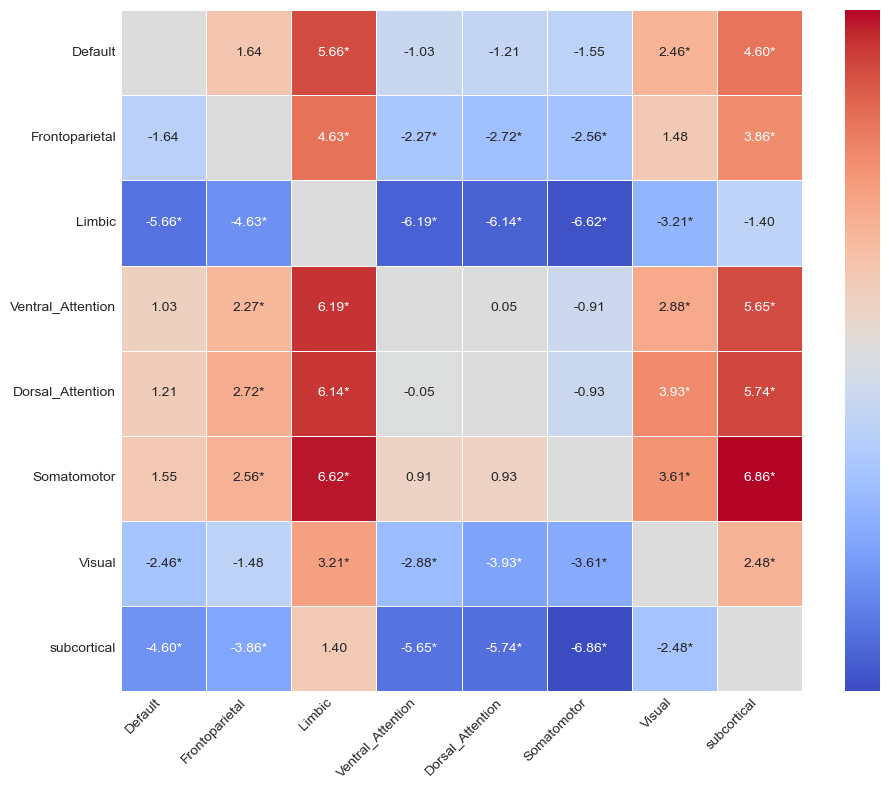

In [5]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ----------------- 0. 基础路径和名称设置 -----------------
base_dir = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype'
out_dir = os.path.join(base_dir, 'Step5_DiffNetwork')
if not os.path.exists(out_dir):
    os.makedirs(out_dir)  # 如果输出文件夹不存在则创建

file1 = os.path.join(base_dir, 'subtype1_INT20_7net_agesex.csv')
file2 = os.path.join(base_dir, 'subtype2_INT20_7net_agesex.csv')

ordered_networks = [
    'Default', 'Frontoparietal', 'Limbic', 'Ventral_Attention',
    'Dorsal_Attention', 'Somatomotor', 'Visual', 'subcortical'
]

# ----------------- 1. 读取数据并计算 差异矩阵 -----------------
df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

data1 = df1[ordered_networks].values
data2 = df2[ordered_networks].values

# 计算  差异矩阵
diff_1 = data1[:, :, np.newaxis] - data1[:, np.newaxis, :]
diff_2 = data2[:, :, np.newaxis] - data2[:, np.newaxis, :]

# ----------------- 2. 提取上三角数据，拉平并与协变量对应保存 -----------------
# 提取上三角索引 (k=1 表示不包含主对角线)，共有 8*7/2 = 28 个连接
upper_tri_indices = np.triu_indices(8, k=1)

# 生成这 28 个连接的名称，例如 "Default-Frontoparietal"
edge_names = [f"{ordered_networks[i]}-{ordered_networks[j]}" for i, j in zip(*upper_tri_indices)]


def flatten_and_merge(df_orig, diff_3d, group_label):
    # 提取所有被试的上三角数据，形状变为 (N, 28)
    flattened_edges = diff_3d[:, upper_tri_indices[0], upper_tri_indices[1]]

    # 转换为 DataFrame
    df_edges = pd.DataFrame(flattened_edges, columns=edge_names)

    # 提取协变量
    df_covariates = df_orig[['subID', 'age', 'sex', 'mean_fd']].copy()
    df_covariates['Group'] = group_label  # 添加组别标签 (1代表Subtype1, 0代表Subtype2)

    # 拼接并返回
    return pd.concat([df_covariates, df_edges], axis=1)


# 处理两组数据并保存
df1_flat = flatten_and_merge(df1, diff_1, group_label=1)
df2_flat = flatten_and_merge(df2, diff_2, group_label=0)

df1_flat.to_csv(os.path.join(out_dir, 'subtype1_edges_flattened.csv'), index=False)
df2_flat.to_csv(os.path.join(out_dir, 'subtype2_edges_flattened.csv'), index=False)
print("需求1已完成：单被试的 28 个网络差异已拉平并与协变量合并保存。")

# ----------------- 3. 控制协变量的组间比较 (OLS回归) -----------------
# 合并两组数据用于统计分析
df_all = pd.concat([df1_flat, df2_flat], ignore_index=True)

# 定义自变量 X (组别 + 年龄 + 性别 + meanFD)
# 注意：我们要看的是 Group 的主效应，Subtype1(1) vs Subtype2(0) 意味着 T为正则 Subtype1的差值更大
X = df_all[['Group', 'age', 'sex', 'mean_fd']]
X = sm.add_constant(X)  # 添加常数项(截距)

t_vals_28 = []
p_vals_28 = []

# 对 28 个连接逐一进行多元线性回归
for edge in edge_names:
    y = df_all[edge]
    model = sm.OLS(y, X).fit()
    # 提取 'Group' 这一项的 t值 和 p值
    t_vals_28.append(model.tvalues['Group'])
    p_vals_28.append(model.pvalues['Group'])

# ----------------- 4. p值校正与 8x8 矩阵还原 -----------------
# 使用 Benjamini/Hochberg 方法对 28 个 P 值进行 FDR 校正
reject, p_vals_corr_28, _, _ = multipletests(p_vals_28, alpha=0.05, method='fdr_bh')

# 初始化 8x8 全零(或全一)矩阵
t_stat_matrix = np.zeros((8, 8))
p_val_corrected_matrix = np.ones((8, 8))

# 将 28 个结果填回上三角
t_stat_matrix[upper_tri_indices] = t_vals_28
p_val_corrected_matrix[upper_tri_indices] = p_vals_corr_28

# 对称地填补至左下角（注意 T 值 A-B 等于 -(B-A)，而 P 值是对称相等的）
# 右上角存的是 row-col，左下角应该是 col-row = -(row-col)
t_stat_matrix.T[upper_tri_indices] = [-t for t in t_vals_28]
p_val_corrected_matrix.T[upper_tri_indices] = p_vals_corr_28

# 保存为 DataFrame
t_map_df = pd.DataFrame(t_stat_matrix, index=ordered_networks, columns=ordered_networks)
p_map_df = pd.DataFrame(p_val_corrected_matrix, index=ordered_networks, columns=ordered_networks)

t_map_df.to_csv(os.path.join(out_dir, 't_map_matrix_covariates.csv'))
p_map_df.to_csv(os.path.join(out_dir, 'p_map_corrected_matrix_covariates.csv'))
print("需求2已完成：控制年龄、性别、meanFD的组间比较已完成并保存。")

# ----------------- 5. 绘制 T-map 热图 -----------------
# 为了让热图更好看，我们创建一个带 '*' 的文本标注矩阵，p_corr < 0.05 的位置打星号
annot_matrix = np.empty((8, 8), dtype=object)
for i in range(8):
    for j in range(8):
        if i == j:
            annot_matrix[i, j] = ""  # 对角线留白
        else:
            t_val = t_stat_matrix[i, j]
            p_val = p_val_corrected_matrix[i, j]
            stars = "*" if p_val < 0.05 else ""  # 如果需要区分 0.01 也可以加 "**"
            # 格式：显示 T 值，如果显著再加个星号
            annot_matrix[i, j] = f"{t_val:.2f}{stars}"

plt.figure(figsize=(10, 8))

# --- 自定义热图颜色 ---
my_colors = ["#00478D", "#7DA2C6", "#FAFDFF", "#D78393", "#B50A27"]
custom_cmap = LinearSegmentedColormap.from_list("custom_diverging", my_colors)

# 绘制热图，应用自定义的 custom_cmap
ax = sns.heatmap(t_map_df, cmap=custom_cmap, center=0,
                 annot=annot_matrix, fmt='',
                 square=True, linewidths=.5,
                 #cbar_kws={"label": "T-value (Subtype1 vs Subtype2)"}
                 )

#plt.title('T-map of Network Differences\n(Controlling for Age, Sex, meanFD; * FDR $p<0.05$)')
plt.xticks(rotation=45, ha='right',fontsize=18)
plt.yticks(rotation=0,fontsize=18)

ax.tick_params(length=0)

vmin = t_map_df.min().min()
vmax = t_map_df.max().max()
cbar = ax.collections[0].colorbar
cbar.set_ticks([])
#cbar.set_ticklabels([f"{vmin:.2f}", f"{vmax:.2f}"])
cbar.ax.tick_params(length=0)
plt.tight_layout()

# 保存热图
heatmap_path = os.path.join(out_dir, 't_map_heatmap2.png')
plt.savefig(heatmap_path, dpi=300, bbox_inches='tight')
print(f"需求3已完成：热图已保存至 {heatmap_path}")
plt.show()

需求3已完成：热图已保存至 /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step5_DiffNetwork/t_map_heatmap2.png


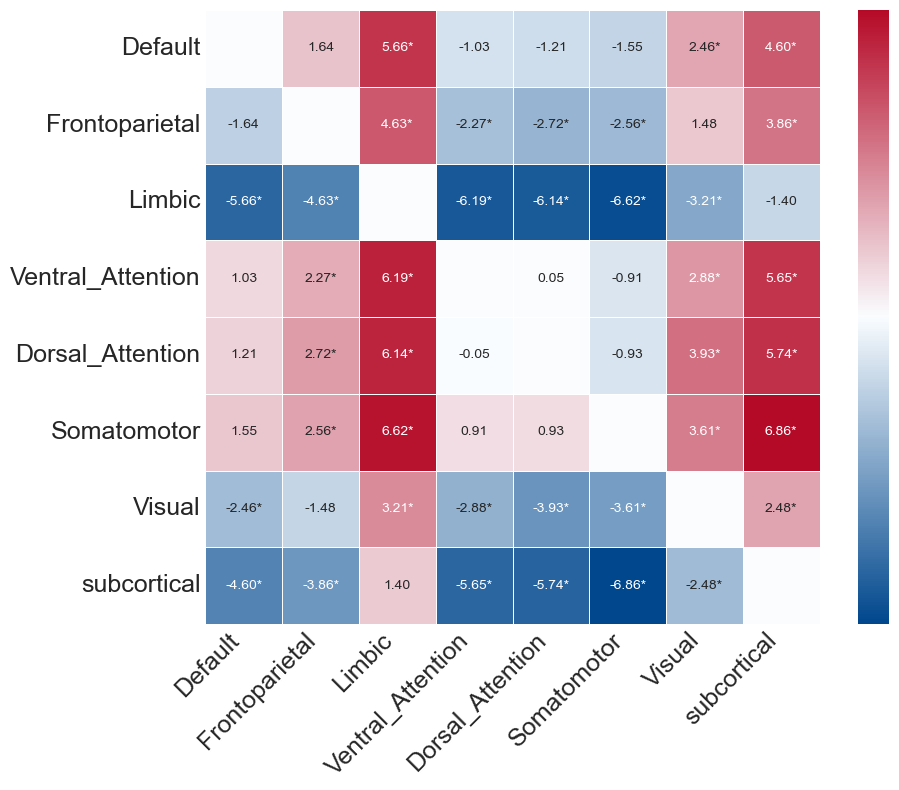

In [8]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib.colors import LinearSegmentedColormap  # 新增导入

# ... [前面的代码保持不变 0~4] ...

# ----------------- 5. 绘制 T-map 热图 -----------------
# 为了让热图更好看，我们创建一个带 '*' 的文本标注矩阵，p_corr < 0.05 的位置打星号
annot_matrix = np.empty((8, 8), dtype=object)
for i in range(8):
    for j in range(8):
        if i == j:
            annot_matrix[i, j] = ""  # 对角线留白
        else:
            t_val = t_stat_matrix[i, j]
            p_val = p_val_corrected_matrix[i, j]
            stars = "*" if p_val < 0.05 else ""  # 如果需要区分 0.01 也可以加 "**"
            # 格式：显示 T 值，如果显著再加个星号
            annot_matrix[i, j] = f"{t_val:.2f}{stars}"

plt.figure(figsize=(10, 8))

# --- 自定义热图颜色 ---
my_colors = ["#00478D", "#7DA2C6", "#FAFDFF", "#D78393", "#B50A27"]
custom_cmap = LinearSegmentedColormap.from_list("custom_diverging", my_colors)

# 绘制热图，应用自定义的 custom_cmap
ax = sns.heatmap(t_map_df, cmap=custom_cmap, center=0,
                 annot=annot_matrix, fmt='',
                 square=True, linewidths=.5,
                 #cbar_kws={"label": "T-value (Subtype1 vs Subtype2)"}
                 )

#plt.title('T-map of Network Differences\n(Controlling for Age, Sex, meanFD; * FDR $p<0.05$)')
plt.xticks(rotation=45, ha='right',fontsize=18)
plt.yticks(rotation=0,fontsize=18)

ax.tick_params(length=0)

vmin = t_map_df.min().min()
vmax = t_map_df.max().max()
cbar = ax.collections[0].colorbar
cbar.set_ticks([])
#cbar.set_ticklabels([f"{vmin:.2f}", f"{vmax:.2f}"])
cbar.ax.tick_params(length=0)
plt.tight_layout()

# 保存热图
heatmap_path = os.path.join(out_dir, 't_map_heatmap2.png')
plt.savefig(heatmap_path, dpi=300, bbox_inches='tight')
print(f"需求3已完成：热图已保存至 {heatmap_path}")
plt.show()

QIDS 亚型间差异比较

In [1]:
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib

# 强制使用 Tkinter 后端弹窗，避免部分 IDE 报错 (如果您在 jupyter 运行，请注释掉此行)
matplotlib.use('TkAgg')

# ================= 配置参数区 =================
target_metric = 'QIDS'  # 分析的指标名称

basepath = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step6_QIDS_Diff/'
file_path1 = basepath + "/subtype1_QIDS.csv"
file_path2 = basepath + "/subtype2_QIDS.csv"

group_name1 = 'Subtype 1'
group_name2 = 'Subtype 2'
# ==============================================

# 1. 读取数据并打上组别标签
df1 = pd.read_csv(file_path1)
df2 = pd.read_csv(file_path2)

df1['Group'] = group_name1
df2['Group'] = group_name2

# 提取所需列并去除含有空值的行，确保统计模型能正常运行
df1 = df1.dropna(subset=[target_metric, 'age', 'sex'])
df2 = df2.dropna(subset=[target_metric, 'age', 'sex'])

orig_len1 = len(df1)
orig_len2 = len(df2)

# 2. 准备两份数据：原始数据 vs 剔除异常值数据 (IQR)
def get_clean_df(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

df1_clean = get_clean_df(df1, target_metric)
df2_clean = get_clean_df(df2, target_metric)

# 合并两份数据集
df_orig = pd.concat([df1, df2], ignore_index=True)
df_clean = pd.concat([df1_clean, df2_clean], ignore_index=True)

# 数据类型强转函数
def format_df(df):
    df['age'] = pd.to_numeric(df['age'], errors='coerce')
    df['sex'] = df['sex'].astype(str)
    df['Group'] = df['Group'].astype('category')
    return df

df_orig = format_df(df_orig)
df_clean = format_df(df_clean)

# 将两份数据放入字典，方便后续循环遍历出图
datasets = {
    "Original": df_orig,
    "Cleaned": df_clean
}

# 全局背景设置
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

custom_palette = {group_name1: '#B50A27', group_name2: '#00478D'}
groups_order = [group_name1, group_name2]
formula = f'{target_metric} ~ C(Group) + age + C(sex)'

# 遍历两份数据并分别单独出图
for data_type, current_df in datasets.items():

    # ---------------- 统计检验 (ANCOVA) ----------------
    model = smf.ols(formula, data=current_df).fit()
    anova_results = anova_lm(model, typ=2)
    p_val = anova_results.loc['C(Group)', 'PR(>F)']
    f_stat = anova_results.loc['C(Group)', 'F']

    print("="*50)
    print(f"当前分析状态: {data_type} Data")
    print(f"样本量: {group_name1}(n={len(current_df[current_df['Group']==group_name1])}) | {group_name2}(n={len(current_df[current_df['Group']==group_name2])})")
    print(f"F 统计量: {f_stat:.4f} | p 值: {p_val:.4f}")
    if p_val < 0.05:
        print("结论: 存在显著差异 (*p < 0.05)")
    else:
        print("结论: 没有显著差异 (p >= 0.05)")

    # ---------------- 每次循环新建一个独立画板 ----------------
    plt.figure(figsize=(8, 6))

    # 绘制箱线图
    ax = sns.boxplot(
        x='Group', y=target_metric, data=current_df,
        order=groups_order, palette=custom_palette, width=0.5,
        showfliers=False, linewidth=1.7,
        boxprops={'facecolor': 'none', 'alpha': 0.8}
    )

    # 核心风格改造：按组别给空心箱体和线条上色
    for i, group_name in enumerate(groups_order):
        group_color = custom_palette[group_name]

        if i < len(ax.patches):
            ax.patches[i].set_facecolor('none')
            ax.patches[i].set_edgecolor(group_color)
            ax.patches[i].set_linewidth(3)

        for j in range(5):
            line_idx = i * 5 + j
            if line_idx < len(ax.lines):
                ax.lines[line_idx].set_color(group_color)
                ax.lines[line_idx].set_linewidth(4)

    # 叠加散点图
    sns.stripplot(
        x='Group', y=target_metric, data=current_df,
        order=groups_order, palette=custom_palette, alpha=0.8,
        size=6, jitter=True
    )

    # 边框加粗
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(3.0)
        spine.set_visible(True)

    # ---------------- 绘制显著性星号 ----------------
    def get_stars(p):
        if p < 0.001: return '***'
        elif p < 0.01: return '**'
        elif p < 0.05: return '*'
        else: return 'ns'

    star_text = get_stars(p_val)

    y_max = current_df[target_metric].max()
    y_min = current_df[target_metric].min()
    y_range = y_max - y_min

    step = 0.08 * y_range
    h = 0.02 * y_range
    current_y = y_max + 0.05 * y_range

    def add_bracket(x1, x2, y, text_star):
        plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=2.5, color='black')
        plt.text((x1 + x2) * 0.5, y, text_star, ha='center', va='bottom', color='black', fontsize=18, fontweight='bold')

    # 仅当有显著差异时才画线
    if star_text != 'ns':
        add_bracket(0, 1, current_y, star_text)
        current_y += step

    # ---------------- 单独处理刻度与 Y 轴范围 ----------------
    plt.ylabel('')  # 清空 Y 轴文字
    plt.xlabel('')
    plt.xticks(fontsize=26)

    if data_type == "Original":
        # 对于 Original 图，修改特定的刻度 [10, 20, 30, 49]
        plt.yticks([10, 20, 30, 40], fontsize=26)
        adjusted_y_min = min(10, y_min - 0.05 * y_range)
        adjusted_y_max = max(50, current_y + 0.1 * y_range) # 留出空间防止 49 或连线被截取
        plt.ylim(adjusted_y_min, adjusted_y_max)
    else:
        # 对于 Cleaned 图，保持默认或常规逻辑
        plt.yticks([10, 15, 20,25],fontsize=26)
        adjusted_y_min = min(5, y_min - 0.05 * y_range)
        adjusted_y_max = max(20, current_y + 0.1 * y_range)
        plt.ylim(adjusted_y_min, adjusted_y_max)

    plt.tight_layout()

    # ---------------- 分别保存文件 ----------------
    save_filename = basepath + f"Fig_{target_metric}_{data_type}_ANCOVA_Comparison.png"
    plt.savefig(save_filename, dpi=300, bbox_inches='tight')
    print(f"✅ 图表已保存至: {save_filename}")

print("="*50)

# 最后统一展示弹窗 (会弹出两个独立窗口)
plt.show()

当前分析状态: Original Data
样本量: Subtype 1(n=133) | Subtype 2(n=148)
F 统计量: 4.6328 | p 值: 0.0322
结论: 存在显著差异 (*p < 0.05)


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_9512/63223092.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_9512/63223092.py:120: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


✅ 图表已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step6_QIDS_Diff/Fig_QIDS_Original_ANCOVA_Comparison.png
当前分析状态: Cleaned Data
样本量: Subtype 1(n=130) | Subtype 2(n=148)
F 统计量: 4.6736 | p 值: 0.0315
结论: 存在显著差异 (*p < 0.05)


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_9512/63223092.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_9512/63223092.py:120: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


✅ 图表已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step6_QIDS_Diff/Fig_QIDS_Cleaned_ANCOVA_Comparison.png


词云结果画图
z-map 映射到大脑生成.nii文件

In [18]:
import pandas as pd
import numpy as np
import nibabel as nib

# ==========================================
# 1. 路径设置 (请根据您的实际环境确认路径)
# ==========================================
# GLM 结果的 CSV 文件路径
csv_path = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step7_Neurosynth/posneg/step1_Subtype2_vs_HC_GLM.csv'
# 您的 CIFTI 大脑模板路径
tpath = '/Users/qingchen/Documents/Data/template/BrainnetomeAtlas/BN_Atlas_freesurfer/fsaverage/fsaverage_LR32k/fsaverage.BN_Atlas.32k_fs_LR.dlabel.nii'
# 输出的 dscalar 文件路径 (建议修改名称以作区分)
output_path = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step7_Neurosynth/posneg/subtype2_zmap_negative.dscalar.nii'

# ==========================================
# 2. 读取并过滤 GLM 结果数据
# ==========================================
df = pd.read_csv(csv_path)

# 提取 z 值和 p 值
z_values = df['z_score'].values
p_values = df['p_value'].values

# 构建过滤后的数值向量 (基于您的要求：显著 p<0.05 且 z<0)
# 满足条件则保留 z_score，否则替换为 0
target_values = np.where((p_values < 0.05) & (z_values < 0), z_values, 0)

# ==========================================
# 3. 加载大脑模板
# ==========================================
template_img = nib.load(tpath)
render_data = template_img.get_fdata().copy()

# 原代码中的标签处理逻辑
render_data[render_data > 210] -= 210

print(f"模板顶点数: {render_data.shape[1]}")
print(f"CSV 中的脑区总数: {len(target_values)}")
print(f"👉 其中满足显著 (p<0.05) 且 Z<0 的脑区数量: {np.sum(target_values != 0)}")

# ==========================================
# 4. 将 Z 值映射到对应的标签索引上
# ==========================================
# 将模板上原来所有的非 0 值先清零，避免残留模板自带的 ID 号
render_data[:] = 0

# 重新加载一遍未清零的原始图来做 mask
orig_data = template_img.get_fdata().copy()
orig_data[orig_data > 210] -= 210

# 遍历 1 到 246 (Brainnetome 246 标准索引)
for i in range(1, len(target_values) + 1):
    mask = (orig_data == i)
    # 将过滤后的 Z 值赋给这些顶点
    render_data[mask] = target_values[i - 1]

# ==========================================
# 5. 构建并保存 CIFTI dscalar 文件
# ==========================================
# 命名此列数据的名称
scalar_axis = nib.cifti2.cifti2_axes.ScalarAxis(['Significant_Negative_Z'])
brain_model_axis = template_img.header.get_axis(1)
new_header = nib.cifti2.Cifti2Header.from_axes((scalar_axis, brain_model_axis))
new_img = nib.Cifti2Image(render_data, header=new_header)
new_img.to_filename(output_path)

print(f"✅ 映射完成！文件已保存至: {output_path}")

模板顶点数: 59412
CSV 中的脑区总数: 246
👉 其中满足显著 (p<0.05) 且 Z<0 的脑区数量: 238
✅ 映射完成！文件已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step7_Neurosynth/posneg/subtype2_zmap_negative.dscalar.nii


词云结果画图
生成词云图

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import numpy as np

# ================== 加载数据 ==================
df = pd.read_csv("/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step7_Neurosynth/posneg/final_Subtype2_Negative_cognitive_p_values.csv")

# 只保留显著正相关的词
df_sig = df[(df['Significant_FDR'] == True) & (df['Real_R'] < 0)]

# 创建 词:权重 字典
freq_dict = dict(zip(df_sig['Term'], df_sig['Real_R']))

# ================== 生成词云 ==================
wordcloud = WordCloud(
    width=1200,
    height=800,
    background_color='white',
    colormap='viridis',           # 或者 'plasma', 'magma', 'inferno'
    prefer_horizontal=0.9,
    max_words=30,
    contour_width=1,
    contour_color='steelblue',
    scale=2,
    relative_scaling=0.5
).generate_from_frequencies(freq_dict)

# ================== 绘图 ==================
plt.figure(figsize=(12, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
# plt.title('Subtype 2 Negative Pattern - Associated Cognitive Terms\n'
#           '(Word size = correlation strength | Only FDR-significant positive associations)',
#           fontsize=14, pad=20)

# 保存高清图片
plt.savefig('/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step7_Neurosynth/posneg/subtype2_negative_wordcloud_python.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("✅ 词云已生成并保存！")

✅ 词云已生成并保存！


词云结果画图 - 自定义颜色

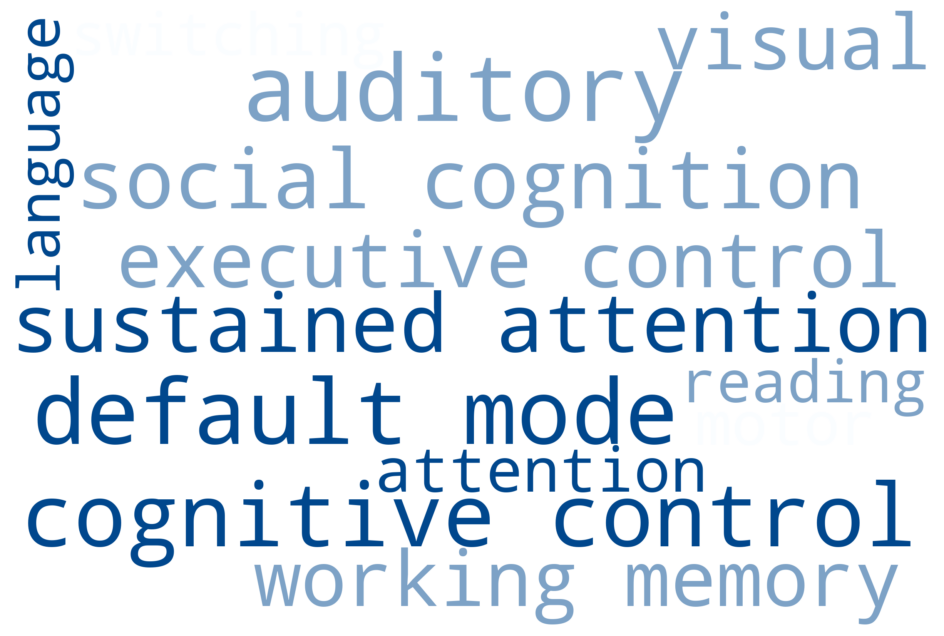

✅ 词云已生成并保存！


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import matplotlib.colors as mcolors  # 新增导入以支持自定义颜色

# ================== 加载数据 ==================
df = pd.read_csv("/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step7_Neurosynth/posneg/final_Subtype2_Negative_cognitive_p_values.csv")

# 只保留显著正相关的词 (注意注释和代码条件的对应关系)
df_sig = df[(df['Significant_FDR'] == True) & (df['Real_R'] < 0)]

# 创建 词:权重 字典
freq_dict = dict(zip(df_sig['Term'], df_sig['Real_R']))

# ================== 设置自定义颜色 ==================
# 你的自定义颜色列表
color_list = ["#00478D", "#7DA2C6", "#FAFDFF"] # "#D78393", "#B50A27"
# 转换为 matplotlib 的 ListedColormap
custom_cmap = mcolors.ListedColormap(color_list)

# ================== 生成词云 ==================
wordcloud = WordCloud(
    width=1200,
    height=800,
    background_color='white',
    colormap=custom_cmap,         # <--- 替换为自定义的 cmap
    prefer_horizontal=0.9,
    max_words=30,
    contour_width=1,
    contour_color='steelblue',
    scale=2,
    relative_scaling=0.5
).generate_from_frequencies(freq_dict)

# ================== 绘图 ==================
plt.figure(figsize=(12, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')

# 保存高清图片
plt.savefig('/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step7_Neurosynth/posneg/subtype2_negative_wordcloud_python.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("✅ 词云已生成并保存！")

HAMD 预测结果画图
散点图

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from nilearn.conftest import matplotlib

matplotlib.use('Agg')
# 读取CSV文件
data_subtype1 = pd.read_csv('/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step8_HAMD_Prediction/PLSR/results.csv')


# 创建一个图和两个轴对象
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(False)

# ========== 新增：去掉背景的核心代码 ==========
# 设置整个画布背景为白色（也可设为None实现透明）
fig.patch.set_facecolor('white')
# 设置坐标轴区域背景为白色（去掉默认的浅灰色背景）
ax.set_facecolor('white')

# 在第一个轴上绘制第一个数据集的散点回归图，增加scatter_kws中的alpha参数设置透明度，设置ci=95显示95%置信区间
sns.regplot(x='y_true', y='y_pred', data=data_subtype1, ax=ax,
            scatter_kws={'color': '#00478D', 'alpha': 0.8,'s':150},  # 设置散点透明度为0.6
            line_kws={'color': '#00478D','linewidth':2.5}, ci=95)  # 添加95%置信区间

# 设置图表标题和坐标轴标签
ax.set_xlabel('Actual score', size=32)
ax.set_ylabel('Predicted score', size=32)
#Prediction score
# 自定义x轴和y轴的刻度
ax.set_xticks([-0.4, 0.0, 0.4, 0.8])
#ax.set_yticks([0.2, 0.4,  0.6, 0.8])

# 增大刻度标签的字体大小
plt.xticks(fontsize=36)  # 增大x轴刻度字体大小
plt.yticks(fontsize=36)  # 增大y轴刻度字体大小

# 设置坐标轴线条属性
for axis in ['left', 'bottom']:
    ax.spines[axis].set_color('black')
    ax.spines[axis].set_linewidth(3)

# 去掉x轴和y轴上的小刻度线
ax.tick_params(axis='both', which='both', bottom=False, top=False, left=False, right=False)

# 去掉上边线和右边线
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# 保存和显示
plt.tight_layout()  # 确保所有元素都适合图形区域
plt.savefig('/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step8_HAMD_Prediction/PLS_results.png', dpi=300)
plt.show()

/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_48488/124377276.py:53: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


HAMD 预测结果画图
weight 映射到大脑

In [31]:
import nibabel as nib
import numpy as np
import scipy.io as sio
import pandas as pd

# 模板文件路径
template_path = '/Users/qingchen/Documents/Data/template/BrainnetomeAtlas/BN_Atlas_freesurfer/fsaverage/fsaverage_LR32k/fsaverage.BN_Atlas.32k_fs_LR.dlabel.nii'
template = template_path
template = nib.load(template)
label=template.get_fdata()
label[label > 210] -= 210

# 找到脑区对应的索引
Regionscsv_path = '/Users/qingchen/Documents/Data/template/BrainnetomeAtlas/region246_network_Yeo.csv'
Regions_data = pd.read_csv(Regionscsv_path)
region = Regions_data['regions'][0:210]

# 加载 CSV 文件 TODO: HC MDD
csv_path = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step8_HAMD_Prediction/PLSR_weight.csv'

weight_data = pd.read_csv(csv_path)

print(weight_data.shape)
# 创建一个新的数组用于存储映射值
mapped_data = np.zeros_like(label)


for i, regionname in enumerate(region):
    print(regionname)
    print(weight_data[regionname][0])
    i = i + 1
    index = np.where(label == i)
    mapped_data[index] = weight_data[regionname][0]



# 检查映射后的数据形状
print("Mapped data shape:", mapped_data.shape)

# 创建 dscalar.nii 文件
scalar_axis = nib.cifti2.cifti2_axes.ScalarAxis(['Mean'])
brain_model_axis = template.header.get_axis(1)
scalar_header = nib.cifti2.Cifti2Header.from_axes((scalar_axis, brain_model_axis))
scalar_img = nib.Cifti2Image(mapped_data, header=scalar_header)

scalar_img.to_filename('/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step8_HAMD_Prediction/PLS_weight.dscalar.nii')




(1, 247)
A8m_L
0.010165734
A8m_R
0.006797653
A8dl_L
0.011057879
A8dl_R
0.001380812
A9l_L
-0.007597599
A9l_R
-0.00306264
A6dl_L
-0.007151126
A6dl_R
-0.004133674
A6m_L
-0.009310384
A6m_R
0.006901869
A9m_L
-0.003069524
A9m_R
0.010015751
A10m_L
-0.008011303
A10m_R
-0.007229758
46d_L
-0.003864264
46d_R
0.00946715
IFJ_L
6.21e-05
IFJ_R
0.020240644
A46_L
0.006948805
A46_R
0.000447856
46v_L
0.013327201
46v_R
0.002374383
A8vl_L
0.009489027
A8vl_R
0.001969464
A6vl_L
0.009659257
A6vl_R
0.009469705
A10l_L
-0.007939896
A10l_R
-0.018873894
A44d_L
0.000458942
A44d_R
0.008974036
IFS_L
-0.007461433
IFS_R
0.015160118
A45c_L
-0.005789449
A45c_R
0.009877377
A45r_L
-0.010790023
A45r_R
-0.010758618
A44op_L
0.00692895
A44op_R
0.008618231
A44v_L
0.001337228
A44v_R
0.005885146
A14m_L
-0.006195201
A14m_R
-0.019806932
47o_L
0.002533202
47o_R
-0.000233579
A11l_L
-0.002537089
A11l_R
0.006461215
A11m_L
-0.016758121
A11m_R
-0.011045785
A13_L
0.000131926
A13_R
-0.011730236
47l_L
-0.00144875
47l_R
-0.003148363
A4hf_L
0

------------------------基因基因基因--------------------------

将final_PLS_brain_regional_scores 的Comp1_Score 列进行 Z-score 标准化

In [5]:
import pandas as pd
from scipy.stats import zscore

# ==========================================
# 1. 文件路径
# ==========================================

input_file = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result_Gene2_Correlation/subtype2/final_PLS_brain_regional_scores.csv'
output_file = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result_Gene2_Correlation/subtype2/final_PLS_brain_regional_scores_Comp1_Zscore.csv'


# ==========================================
# 2. 读取 CSV 文件
# ==========================================

df = pd.read_csv(input_file)

print("原始数据前5行：")
print(df.head())


# ==========================================
# 3. 对 Comp1_Score 列进行 Z-score
# ==========================================

df['Comp1_Score'] = zscore(
    df['Comp1_Score'],
    ddof=1,
    nan_policy='omit'
)


# ==========================================
# 4. 查看标准化结果
# ==========================================

print("\nZ-score 后 Comp1_Score 统计信息：")
print(df['Comp1_Score'].describe())


# ==========================================
# 5. 保存新文件
# ==========================================

df.to_csv(
    output_file,
    index=False
)

print(f"\n✅ Z-score 标准化完成！")
print(f"新文件保存至：{output_file}")

原始数据前5行：
            ROI_ID  Comp1_Score  Comp2_Score  Comp3_Score
0  BN_Cortex_ROI_1     8.798502    36.071102   -21.970954
1  BN_Cortex_ROI_2     5.961175    33.741371   -21.410943
2  BN_Cortex_ROI_3     5.723752    28.358279   -12.266094
3  BN_Cortex_ROI_4    10.460829    25.027036    -0.104134
4  BN_Cortex_ROI_5   -13.862865     1.034909    -0.929543

Z-score 后 Comp1_Score 统计信息：
count    2.100000e+02
mean     5.815454e-18
std      1.000000e+00
min     -3.733465e+00
25%     -4.515401e-01
50%      2.925371e-01
75%      6.722960e-01
max      1.460373e+00
Name: Comp1_Score, dtype: float64

✅ Z-score 标准化完成！
新文件保存至：/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result_Gene2_Correlation/subtype2/final_PLS_brain_regional_scores_Comp1_Zscore.csv


基因-zmap 和 comp_1（第一主成分）相关性   subtype1

Scaled PLS score Min: -1.0000
Scaled PLS score Max: 0.4034
r value: 0.47639118286225934 p value: 2.6996888458986584e-13


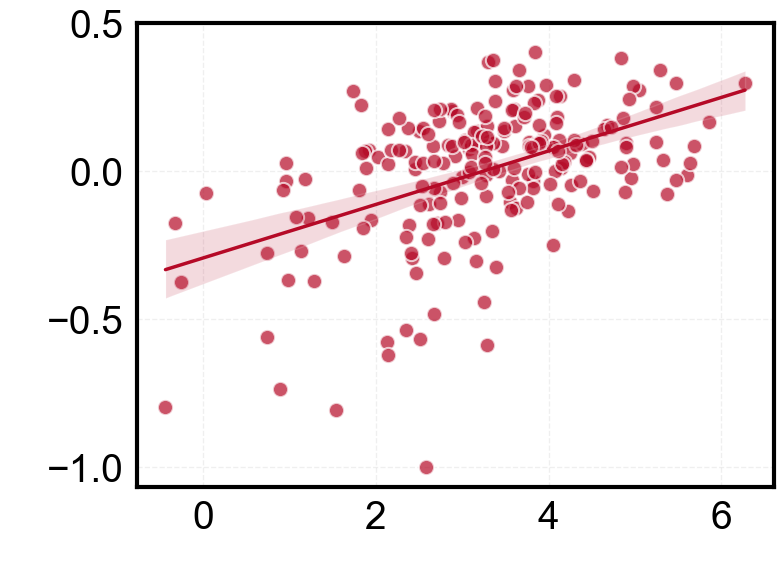

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
import warnings

warnings.filterwarnings('ignore')

# =====================================
# 1. 加载数据
# =====================================
zmap_df = pd.read_csv('/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result_Gene2_Correlation/subtype1/final_PLS_brain_regional_scores.csv')
pls_df = pd.read_csv('/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result_Gene2_Correlation/subtype1/final_PLS_brain_regional_scores.csv')

# =====================================
# 2. 提取、对齐与缩放
# =====================================
z_values = zmap_df["INT_input_statistic"].values
pls1_scores_raw = pls_df['PLS1_score_display'].values

max_abs_val = np.nanmax(np.abs(pls1_scores_raw))
pls1_scores_scaled = pls1_scores_raw / max_abs_val

# 打印缩放后的最大值和最小值
scaled_min = np.nanmin(pls1_scores_scaled)
scaled_max = np.nanmax(pls1_scores_scaled)

print(f"Scaled PLS score Min: {scaled_min:.4f}")
print(f"Scaled PLS score Max: {scaled_max:.4f}")

valid_mask = ~np.isnan(pls1_scores_scaled)
x_valid = z_values[valid_mask]
y_valid = pls1_scores_scaled[valid_mask]

r_val, p_val = pearsonr(x_valid, y_valid)
print("r value:", r_val, "p value:", p_val)

# =====================================
# 3. 绘制精美散点图 (纯白背景)
# =====================================
fig = plt.figure(figsize=(8, 6), facecolor='white')
ax = plt.gca()
ax.set_facecolor('white')

# 🌟 在此处调节散点的大小与透明度
SCATTER_SIZE = 120       # 默认是 40，数值越大点越大
SCATTER_ALPHA = 0.7     # 范围 0 到 1，1 为完全不透明，0 为完全透明

# 使用 seaborn 画图
sns.regplot(
    x=x_valid,
    y=y_valid,
    scatter_kws={
        'alpha': SCATTER_ALPHA,
        'color': '#B50A27',
        's': SCATTER_SIZE,
        'edgecolor': 'white',
        'linewidths': 1.5  # 适当调小了白边的宽度，防止点太小被白边吞没
    },
    line_kws={'color': '#B50A27', 'linewidth': 2.5}
)

plt.xlabel(' ', fontsize=24, fontname='Arial')
plt.ylabel(' ', fontsize=24, fontname='Arial')

# -------------------------------------
# 🌟 修复区域：强制指定边框颜色并保留四边
# -------------------------------------
for spine_name in ['top', 'right', 'bottom', 'left']:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_color('black')  # 强制显色！解决消失问题
    ax.spines[spine_name].set_linewidth(3)

#ax.set_xticks([0, 2, 4, 6])
ax.set_yticks([-1, -0.5, 0.0, 0.5])

TICK_LABEL_SIZE = 28
plt.tick_params(axis='both', which='major', labelsize=TICK_LABEL_SIZE, width=1.5, length=6, colors='black')

plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()

plt.savefig(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result_Gene2_Correlation/subtype1/Fig_PLS1_vs_Zmap_Scatter_Final_Scaled.png',
    dpi=600,
    facecolor='white',
    transparent=False
)
plt.show()

基因-zmap 和 comp_1（第一主成分）相关性   subtype2

Scaled PLS score Min: -1.0000
Scaled PLS score Max: 0.3681
r value: -0.5124879259273433 p value: 1.8429591815269827e-15


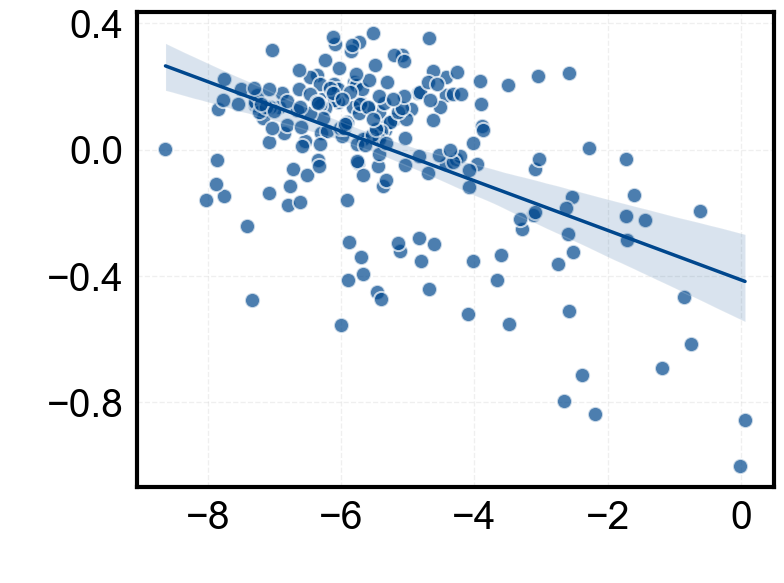

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
import warnings

warnings.filterwarnings('ignore')

# =====================================
# 1. 加载数据
# =====================================
zmap_df = pd.read_csv('/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result_Gene2_Correlation/subtype2/final_PLS_brain_regional_scores.csv')
pls_df = pd.read_csv('/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result_Gene2_Correlation/subtype2/final_PLS_brain_regional_scores.csv')

# =====================================
# 2. 提取、对齐与缩放
# =====================================
z_values = zmap_df["INT_input_statistic"].values
pls1_scores_raw = pls_df['PLS1_score_display'].values

max_abs_val = np.nanmax(np.abs(pls1_scores_raw))
pls1_scores_scaled = pls1_scores_raw / max_abs_val

# 打印缩放后的最大值和最小值
scaled_min = np.nanmin(pls1_scores_scaled)
scaled_max = np.nanmax(pls1_scores_scaled)

print(f"Scaled PLS score Min: {scaled_min:.4f}")
print(f"Scaled PLS score Max: {scaled_max:.4f}")


valid_mask = ~np.isnan(pls1_scores_scaled)
x_valid = z_values[valid_mask]
y_valid = pls1_scores_scaled[valid_mask]

r_val, p_val = pearsonr(x_valid, y_valid)
print("r value:", r_val, "p value:", p_val)

# =====================================
# 3. 绘制精美散点图 (纯白背景)
# =====================================
fig = plt.figure(figsize=(8, 6), facecolor='white')
ax = plt.gca()
ax.set_facecolor('white')

# 🌟 在此处调节散点的大小与透明度
SCATTER_SIZE = 120       # 默认是 40，数值越大点越大
SCATTER_ALPHA = 0.7     # 范围 0 到 1，1 为完全不透明，0 为完全透明

# 使用 seaborn 画图
sns.regplot(
    x=x_valid,
    y=y_valid,
    scatter_kws={
        'alpha': SCATTER_ALPHA,
        'color': '#00478D',
        's': SCATTER_SIZE,
        'edgecolor': 'white',
        'linewidths': 1.5  # 适当调小了白边的宽度，防止点太小被白边吞没
    },
    line_kws={'color': '#00478D', 'linewidth': 2.5}
)

plt.xlabel(' ', fontsize=24, fontname='Arial')
plt.ylabel(' ', fontsize=24, fontname='Arial')

# -------------------------------------
# 🌟 修复区域：强制指定边框颜色并保留四边
# -------------------------------------
for spine_name in ['top', 'right', 'bottom', 'left']:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_color('black')  # 强制显色！解决消失问题
    ax.spines[spine_name].set_linewidth(3)

ax.set_xticks([-8,-6, -4, -2, 0])
ax.set_yticks([-0.8, -0.4, 0.0, 0.4])

TICK_LABEL_SIZE = 28
plt.tick_params(axis='both', which='major', labelsize=TICK_LABEL_SIZE, width=1.5, length=6, colors='black')

plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()

plt.savefig(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result_Gene2_Correlation/subtype2/PLS1_vs_Zmap_Scatter_Final_Scaled.png',
    dpi=600,
    facecolor='white',
    transparent=False
)
plt.show()

基因- score 映射到大脑皮层上展示

In [29]:
import pandas as pd
import numpy as np
import nibabel as nib

# 1. 路径设置
# 之前步骤生成的包含均值的 CSV 文件 (subtype1_PLS_brain_regional_scores.csv)
csv_path = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result1_zmap/subtype2_Zmap_plot.csv'
# 大脑模板路径
tpath = '/Users/qingchen/Documents/Data/template/BrainnetomeAtlas/BN_Atlas_freesurfer/fsaverage/fsaverage_LR32k/fsaverage.BN_Atlas.32k_fs_LR.dlabel.nii'
# 输出的 dscalar 文件路径
output_path = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result1_zmap/subtype2_Zmap_plot.dscalar.nii'

# 2. 读取 CSV 数据
df = pd.read_csv(csv_path)
# 排除 'region' 辅助列，获取脑区数据
data_values = df.drop(columns=['region']).values

# 🌟 核心修改：MaxAbs Scaling 缩放
max_abs_val = np.nanmax(np.abs(data_values))
data_values_scaled = data_values / max_abs_val
print(f"数据已通过 MaxAbs 缩放！计算使用的最大绝对值为: {max_abs_val:.4f}")

# 3. 加载大脑模板
template_img = nib.load(tpath)
render_data = template_img.get_fdata().copy()

# 标签处理逻辑
render_data[render_data > 210] -= 210

print(f"模板顶点数: {render_data.shape[1]}")
print(f"待映射的脑区数: {data_values_scaled.shape[1]}")

# 4. 将缩放后的数值映射到对应的标签索引上
for i in range(1, data_values_scaled.shape[1] + 1):
    mask = (render_data == i)
    # 将缩放后的值赋给对应顶点
    render_data[mask] = data_values_scaled[0, i - 1]

# 5. 构建并保存 CIFTI dscalar 文件
# 更新列名以反映缩放后的数据
scalar_axis = nib.cifti2.cifti2_axes.ScalarAxis(['Mean_INT_Scaled'])
brain_model_axis = template_img.header.get_axis(1)
new_header = nib.cifti2.Cifti2Header.from_axes((scalar_axis, brain_model_axis))
new_img = nib.Cifti2Image(render_data, header=new_header)
new_img.to_filename(output_path)

print(f"映射完成！文件已保存至: {output_path}")

数据已通过 MaxAbs 缩放！计算使用的最大绝对值为: 8.6412
模板顶点数: 59412
待映射的脑区数: 246
映射完成！文件已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result1_zmap/subtype2_Zmap_plot.dscalar.nii


基因 -  PLS1 loading

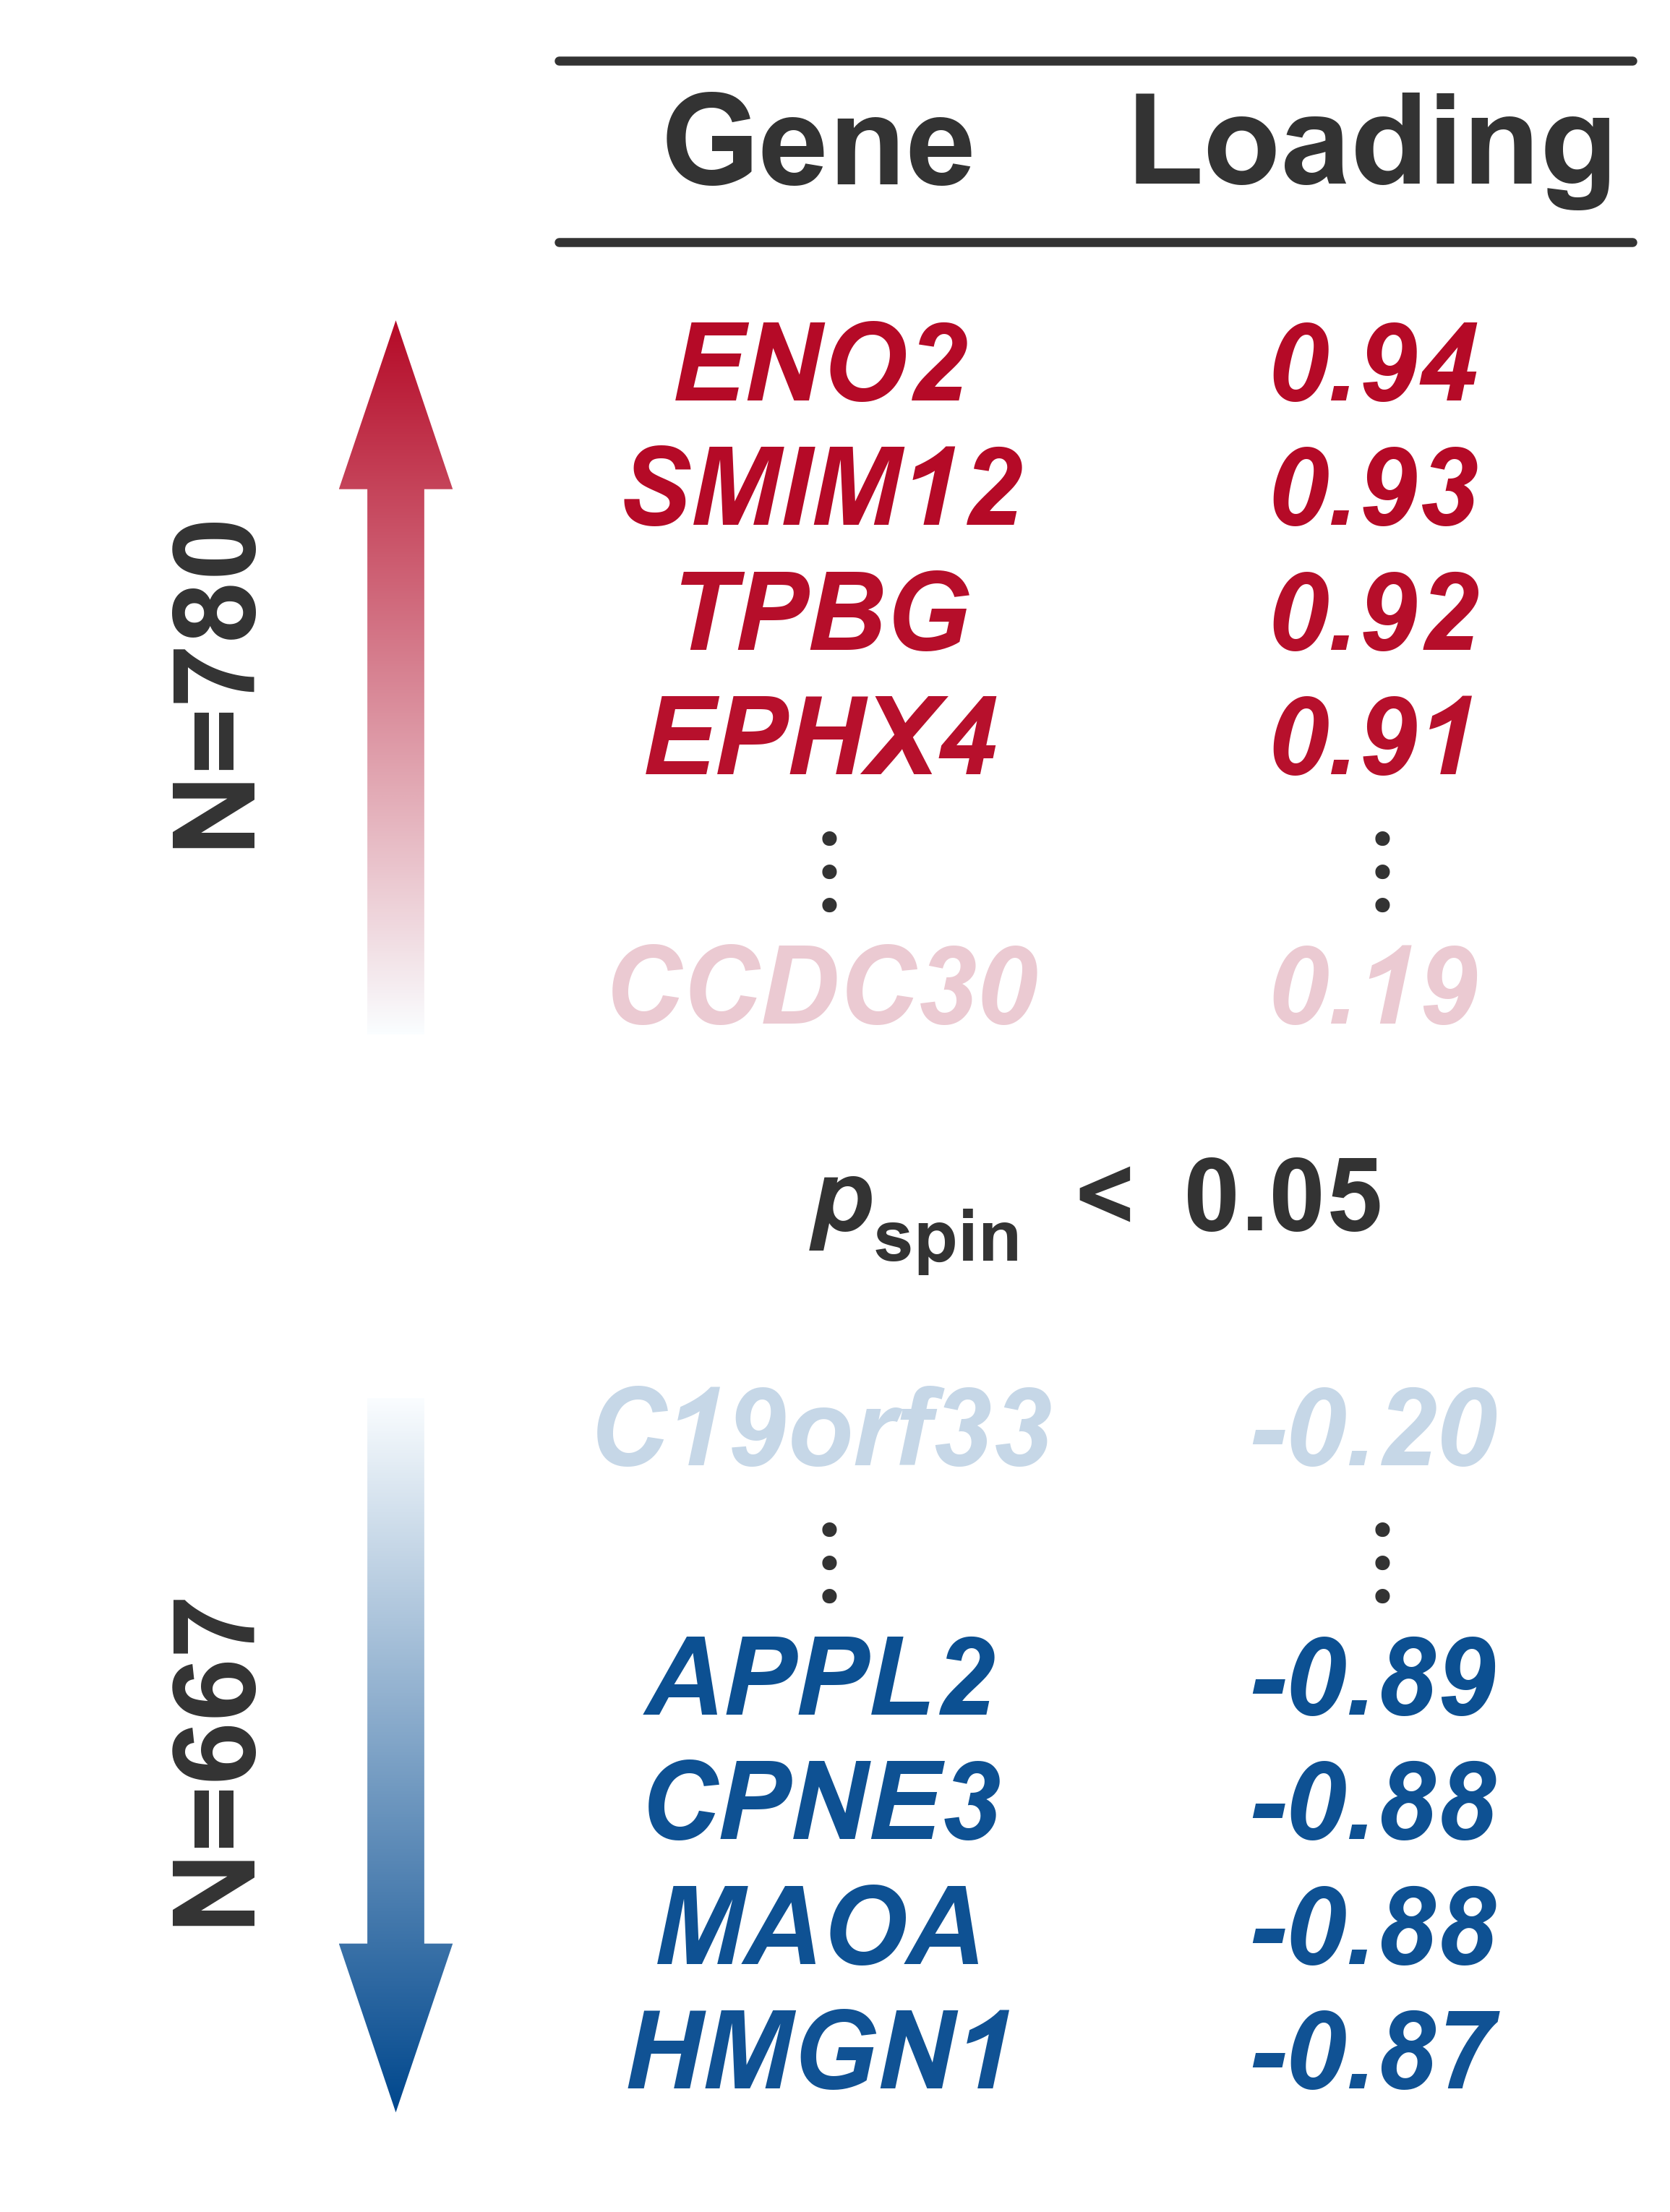


Figure saved successfully!
PNG: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result_Gene2_Correlation/subtype1/S1_Comp1_Gene_Loading.png


In [22]:
import os
from decimal import Decimal, ROUND_HALF_UP

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Polygon


# ============================================================
# 1. 文件路径
# ============================================================

output_dir = (
    "/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/"
    "INT_covariate/Step2_subtype/Step18_Genetic/"
    "result_Gene2_Correlation/subtype1/"
)

positive_file = os.path.join(
    output_dir, "PLS1_positive_candidates.csv"
)

negative_file = os.path.join(
    output_dir, "PLS1_negative_candidates.csv"
)

os.makedirs(output_dir, exist_ok=True)


# ============================================================
# 2. 基本参数
# ============================================================

N_TOP = 4
N_BOTTOM = 1

FONT_FAMILY = "Arial"
DECIMALS = 2

# 所有字号统一在这里调整
FONT_TITLE = 42       # 原来 36
FONT_GENE = 36        # 原来 30
FONT_ELLIPSIS = 38    # 原来 32
FONT_PSPIN = 34       # 原来 28
FONT_N = 38           # 原来 32


# ============================================================
# 3. 全局字体设置
# ============================================================

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",

    "mathtext.fontset": "custom",
    "mathtext.rm": "Arial",
    "mathtext.it": "Arial:italic",
    "mathtext.bf": "Arial:bold",
    "mathtext.bfit": "Arial:italic:bold",

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 600
})


# ============================================================
# 4. 自定义颜色
# ============================================================

COLORS = [
    "#00478D",
    "#7DA2C6",
    "#FAFDFF",
    "#D78393",
    "#B50A27"
]

cmap = LinearSegmentedColormap.from_list(
    "Blue_White_Red",
    COLORS,
    N=256
)


# ============================================================
# 5. 读取并检查数据
# ============================================================

positive_df = pd.read_csv(positive_file)
negative_df = pd.read_csv(negative_file)

gene_col = "Gene"
loading_col = "Loading"

for name, df in [
    ("Positive", positive_df),
    ("Negative", negative_df)
]:
    for col in [gene_col, loading_col]:
        if col not in df.columns:
            raise ValueError(f"{name} 文件中没有找到列: {col}")

    if df.empty:
        raise ValueError(f"{name} 文件没有数据")

    df[loading_col] = pd.to_numeric(
        df[loading_col],
        errors="raise"
    )

    if not np.isfinite(
        df[loading_col].to_numpy(dtype=float)
    ).all():
        raise ValueError(f"{name} 文件的 Loading 包含无效值")

if N_TOP < 1 or N_BOTTOM < 1:
    raise ValueError("N_TOP 和 N_BOTTOM 必须至少为 1")


# ============================================================
# 6. 数据排序及基因选择
# ============================================================

positive_df = positive_df.sort_values(
    loading_col,
    ascending=False
).reset_index(drop=True)

negative_df = negative_df.sort_values(
    loading_col,
    ascending=True
).reset_index(drop=True)

pos_top = positive_df.head(N_TOP)
pos_bottom = positive_df.tail(N_BOTTOM)

neg_top = negative_df.head(N_TOP)
neg_bottom = negative_df.tail(N_BOTTOM)

n_positive = len(positive_df)
n_negative = len(negative_df)


# ============================================================
# 7. Loading 颜色范围
# ============================================================

all_loading = np.concatenate([
    positive_df[loading_col].to_numpy(dtype=float),
    negative_df[loading_col].to_numpy(dtype=float)
])

max_abs = np.max(np.abs(all_loading))

if max_abs == 0:
    raise ValueError("Loading 不能全部为 0")

norm = TwoSlopeNorm(
    vmin=-max_abs,
    vcenter=0,
    vmax=max_abs
)


# ============================================================
# 8. 严格四舍五入
# ============================================================

def format_loading(value, decimals=DECIMALS):
    quantizer = Decimal("1").scaleb(-decimals)

    rounded_value = Decimal(str(value)).quantize(
        quantizer,
        rounding=ROUND_HALF_UP
    )

    return f"{rounded_value:.{decimals}f}"


# ============================================================
# 9. 布局参数
# ============================================================

# 两个箭头共用同一个横坐标，保证上下对齐
x_arrow = 0.23
x_n = 0.12

# 增大两列之间的距离，适应放大后的字体
x_gene = 0.49
x_loading = 0.83

GENE_SPACING = 0.048
BLOCK_SPACING = 0.085

line_color = "#333333"


# ============================================================
# 10. 计算各行 Y 坐标
# ============================================================

y_cursor = 0.865

pos_top_y = [
    y_cursor - i * GENE_SPACING
    for i in range(len(pos_top))
]

pos_ellipsis_y = pos_top_y[-1] - GENE_SPACING

y_cursor = pos_ellipsis_y - GENE_SPACING

pos_bottom_y = [
    y_cursor - i * GENE_SPACING
    for i in range(len(pos_bottom))
]

p_spin_y = pos_bottom_y[-1] - BLOCK_SPACING

y_cursor = p_spin_y - BLOCK_SPACING

neg_bottom_y = [
    y_cursor - i * GENE_SPACING
    for i in range(len(neg_bottom))
]

neg_ellipsis_y = neg_bottom_y[-1] - GENE_SPACING

y_cursor = neg_ellipsis_y - GENE_SPACING

neg_top_y = [
    y_cursor - i * GENE_SPACING
    for i in range(len(neg_top))
]


# ============================================================
# 11. 创建画布并去除底部多余留白
# ============================================================

fig = plt.figure(
    figsize=(7.5, 10),
    dpi=300,
    facecolor="white"
)

ax = fig.add_axes([0, 0, 1, 1])

ax.set_xlim(0, 1)
ax.set_ylim(neg_top_y[-1] - 0.05, 1)
ax.axis("off")


# ============================================================
# 12. 顶部横线与标题
# ============================================================

for y_line in [0.985, 0.915]:
    ax.plot(
        [0.33, 0.99],
        [y_line, y_line],
        color=line_color,
        linewidth=3,
        solid_capstyle="round"
    )

for x, title in [
    (x_gene, "Gene"),
    (x_loading, "Loading")
]:
    ax.text(
        x,
        0.95,
        title,
        ha="center",
        va="center",
        fontsize=FONT_TITLE,
        fontweight="bold",
        color=line_color,
        fontfamily=FONT_FAMILY
    )


# ============================================================
# 13. 基因与 Loading 绘制函数
# ============================================================

def draw_gene_row(ax, gene, loading, y):
    color = cmap(norm(loading))

    text_style = {
        "ha": "center",
        "va": "center",
        "fontsize": FONT_GENE,
        "fontweight": "bold",
        "fontstyle": "italic",
        "color": color,
        "fontfamily": FONT_FAMILY,
        "zorder": 3
    }

    ax.text(
        x_gene,
        y,
        str(gene),
        **text_style
    )

    ax.text(
        x_loading,
        y,
        format_loading(loading),
        **text_style
    )


def draw_gene_block(df, y_positions):
    for (_, row), y in zip(df.iterrows(), y_positions):
        draw_gene_row(
            ax=ax,
            gene=row[gene_col],
            loading=row[loading_col],
            y=y
        )


def draw_ellipsis(y):
    for x in [x_gene, x_loading]:
        ax.text(
            x,
            y,
            r"$\vdots$",
            ha="center",
            va="center",
            fontsize=FONT_ELLIPSIS,
            fontweight="bold",
            color=line_color,
            fontfamily=FONT_FAMILY
        )


# ============================================================
# 14. 绘制基因及省略号
# ============================================================

draw_gene_block(pos_top, pos_top_y)
draw_ellipsis(pos_ellipsis_y)
draw_gene_block(pos_bottom, pos_bottom_y)

draw_gene_block(neg_bottom, neg_bottom_y)
draw_ellipsis(neg_ellipsis_y)
draw_gene_block(neg_top, neg_top_y)


# ============================================================
# 15. 中间 p_spin 标注
# ============================================================

ax.text(
    (x_gene + x_loading) / 2,
    p_spin_y,
    r"$\mathbf{\mathit{p}}_{\mathbf{spin}}"
    r"\ \mathbf{<}\ \mathbf{0.05}$",
    ha="center",
    va="center",
    fontsize=FONT_PSPIN,
    fontweight="bold",
    color=line_color,
    fontfamily=FONT_FAMILY
)


# ============================================================
# 16. 对称渐变箭头函数
#     向下箭头由向上箭头镜像生成，保证轮廓对称
# ============================================================

def draw_gradient_arrow(
    ax,
    x,
    y_bottom,
    y_top,
    direction,
    color_start,
    color_end,
    shaft_width=0.035,
    head_width=0.070,
    head_height=0.065
):
    if direction not in ("up", "down"):
        raise ValueError("direction 必须为 'up' 或 'down'")

    if y_top <= y_bottom:
        raise ValueError("y_top 必须大于 y_bottom")

    head_height = min(
        head_height,
        (y_top - y_bottom) * 0.4
    )

    shaft_half = shaft_width / 2
    head_half = head_width / 2
    head_base_y = y_top - head_height

    # 先构造左右对称的向上箭头
    vertices = np.array([
        [x - shaft_half, y_bottom],
        [x + shaft_half, y_bottom],
        [x + shaft_half, head_base_y],
        [x + head_half, head_base_y],
        [x, y_top],
        [x - head_half, head_base_y],
        [x - shaft_half, head_base_y]
    ], dtype=float)

    gradient = np.linspace(0, 1, 512).reshape(-1, 1)

    if direction == "down":
        # 沿箭头的水平中线镜像
        vertices[:, 1] = (
            y_bottom + y_top - vertices[:, 1]
        )
        gradient = gradient[::-1]

    arrow_cmap = LinearSegmentedColormap.from_list(
        f"arrow_gradient_{direction}",
        [color_start, color_end],
        N=256
    )

    arrow_patch = Polygon(
        vertices,
        closed=True,
        facecolor="none",
        edgecolor="none"
    )

    ax.add_patch(arrow_patch)

    gradient_img = ax.imshow(
        gradient,
        cmap=arrow_cmap,
        vmin=0,
        vmax=1,
        aspect="auto",
        extent=[
            x - head_half,
            x + head_half,
            y_bottom,
            y_top
        ],
        origin="lower",
        interpolation="bilinear",
        zorder=1
    )

    gradient_img.set_clip_path(arrow_patch)


# ============================================================
# 17. 绘制上下箭头
# ============================================================

pos_arrow_bottom = pos_bottom_y[-1] - 0.015
pos_arrow_top = pos_top_y[0] + 0.020

neg_arrow_bottom = neg_top_y[-1] - 0.020
neg_arrow_top = neg_bottom_y[0] + 0.015

draw_gradient_arrow(
    ax=ax,
    x=x_arrow,
    y_bottom=pos_arrow_bottom,
    y_top=pos_arrow_top,
    direction="up",
    color_start="#FAFDFF",
    color_end="#B50A27"
)

draw_gradient_arrow(
    ax=ax,
    x=x_arrow,
    y_bottom=neg_arrow_bottom,
    y_top=neg_arrow_top,
    direction="down",
    color_start="#FAFDFF",
    color_end="#00478D"
)


# ============================================================
# 18. 左侧 N 标签
# ============================================================

pos_arrow_mid = (
    pos_arrow_bottom + pos_arrow_top
) / 2

neg_arrow_mid = (
    neg_arrow_bottom + neg_arrow_top
) / 2

for y, count in [
    (pos_arrow_mid, n_positive),
    (neg_arrow_mid, n_negative)
]:
    ax.text(
        x_n,
        y,
        f"N={count}",
        rotation=90,
        ha="center",
        va="center",
        fontsize=FONT_N,
        fontweight="bold",
        color=line_color,
        fontfamily=FONT_FAMILY
    )


# ============================================================
# 19. 保存 PNG
# ============================================================

png_file = os.path.join(
    output_dir,
    "S1_Comp1_Gene_Loading.png"
)

fig.savefig(
    png_file,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.03,
    facecolor="white"
)

plt.show()

print("\nFigure saved successfully!")
print("PNG:", png_file)

基因-气泡图

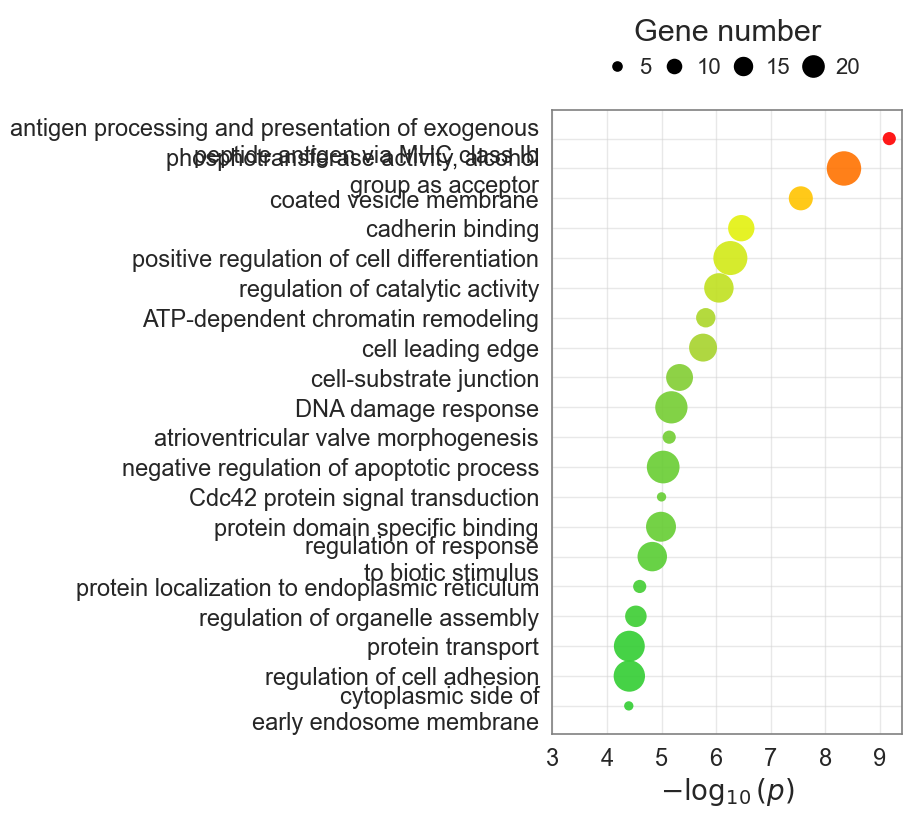

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

# 读取数据
df = pd.read_csv('/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result_Gene3_Enrich/subtype1/GO_S1_neg.csv')
outpath = "/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step18_Genetic/result_Gene3_Enrich/subtype1/"

# 按 Log10(P) 排序，使最显著的通路在图表上方
df = df.sort_values(by='Log10(P)', ascending=True).reset_index(drop=True)

# 格式化 Y 轴标签：如果单词数大于 5，则在中间位置折行
def format_label(text):
    words = str(text).split()
    if len(words) > 5:
        mid = (len(words) + 1) // 2
        return " ".join(words[:mid]) + "\n" + " ".join(words[mid:])
    return text

df['Description_wrapped'] = df['Description'].apply(format_label)

# 1. 创建画布并显式设置背景为白色
fig, ax = plt.subplots(figsize=(7, 8), facecolor='white')
ax.set_facecolor('white')

# 自定义颜色映射（绿 -> 黄绿 -> 黄 -> 橙 -> 红）
cmap = mcolors.LinearSegmentedColormap.from_list(
    "custom_g_r", ["#32CD32", "#9ACD32", "#FFFF00", "#FFA500", "#FF0000"]
)

# 绘制气泡散点图
size_scaling = 15
scatter = ax.scatter(x=df['Log10(P)'],
                     y=df['Description_wrapped'],
                     s=df['Count'] * size_scaling,
                     c=df['Log10(P)'],
                     cmap=cmap,
                     edgecolors='none',
                     alpha=0.9)

# 设置网格与边框样式
ax.grid(True, linestyle='-', color='lightgray', alpha=0.5)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_color('gray')

# 2. 去除右侧 colorbar，并在气泡图最底部 X 轴添加 -log(p) 标签
ax.set_xlabel(r'$-\log_{10}(p)$', fontsize=20)
ax.set_ylabel('')
ax.set_xticks(range(3, 10))

# 调大 X 轴与 Y 轴的字体大小
ax.tick_params(axis='both', which='major', labelsize=17)

# 3. 将 count 放置到图正上方，横置放置 (使用 ncol=4)
legend_elements = []
for val in [5, 10, 15, 20]:
    legend_elements.append(Line2D([0], [0], marker='o', color='w',
                                  markerfacecolor='black',
                                  markersize=(val * size_scaling)**0.5,
                                  label=str(val)))

# 放置图例到坐标轴正上方，新增 columnspacing=0.8 缩小圆点之间的间距
ax.legend(handles=legend_elements, title='Gene number', loc='lower center',
          bbox_to_anchor=(0.5, 1.02), ncol=4, frameon=False,
          fontsize=16, title_fontsize=22, handletextpad=0.01, columnspacing=0.01)

# 调整主图区域防止与上方图例重叠，并释放原本留给右侧 colorbar 的空间
plt.subplots_adjust(left=0.45, right=0.95, top=0.88, bottom=0.1)

# 保存与展示，确保保存出的图片背景也是白色
plt.savefig(outpath+'/s1neg.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

ARI 折线图

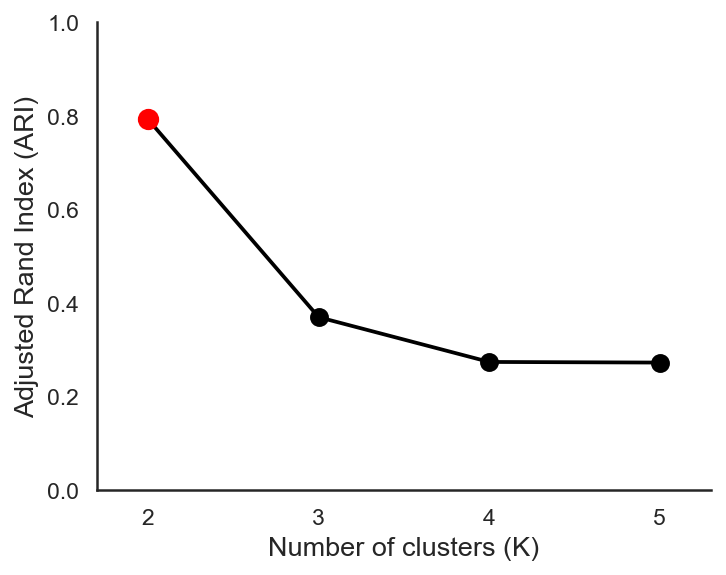

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# ==============================
# 1. 数据
# ==============================
K = np.array([2, 3, 4, 5])
ARI = np.array([
    0.791818447237466,
    0.3691769917436624,
    0.2735516456080178,
    0.27221949249573696
])

# ==============================
# 2. 绘图参数
# ==============================
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,
    'axes.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

fig, ax = plt.subplots(figsize=(5, 4), dpi=150)

# 黑色折线
ax.plot(
    K, ARI,
    color='black',
    linewidth=1.8,
    zorder=1
)

# 其他 K 值：黑色圆点
ax.scatter(
    K[1:], ARI[1:],
    color='black',
    s=65,
    zorder=3
)

# K=2：红色圆点
ax.scatter(
    K[0], ARI[0],
    color='red',
    s=85,
    zorder=4
)

# ==============================
# 3. 坐标轴设置
# ==============================
ax.set_xlabel('Number of clusters (K)', fontsize=13)
ax.set_ylabel('Adjusted Rand Index (ARI)', fontsize=13)

ax.set_xticks(K)
ax.set_xlim(1.7, 5.3)
ax.set_ylim(0, 1.0)

ax.tick_params(
    axis='both',
    direction='out',
    length=5,
    width=1.2,
    labelsize=11
)

# 去除上、右边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# 不显示网格
ax.grid(False)

plt.tight_layout()

# ==============================
# 4. 保存图片
# ==============================
plt.savefig(
    'ARI_cluster_stability.png',
    dpi=600,
    bbox_inches='tight'
)

plt.savefig(
    'ARI_cluster_stability.pdf',
    bbox_inches='tight'
)
plt.savefig('/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/HYDRA/ARI.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


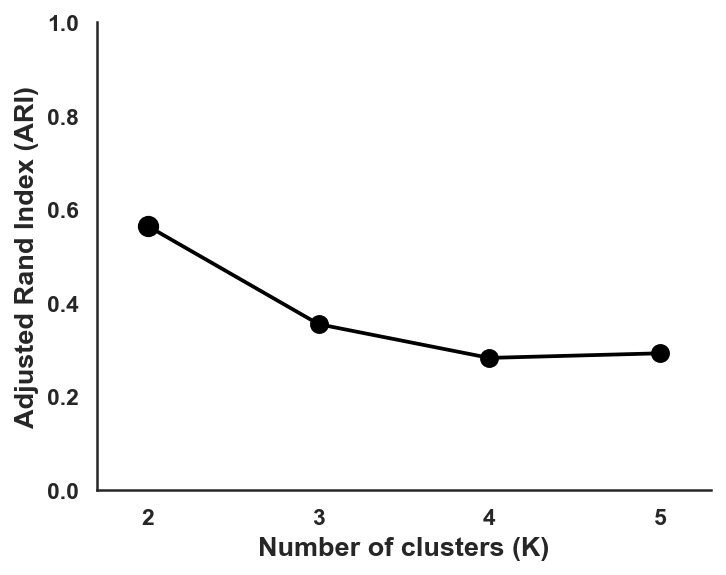

In [28]:

import numpy as np
import matplotlib.pyplot as plt

# ==============================
# 1. 数据
# ==============================
K = np.array([2, 3, 4, 5])
ARI = np.array([

0.563482886566903,
0.354239426866890,
0.282181531647343,
0.292038808247494,



])

# ==============================
# 2. 绘图参数
# ==============================
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,
    'axes.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

fig, ax = plt.subplots(figsize=(5, 4), dpi=150)

# 黑色折线
ax.plot(
    K, ARI,
    color='black',
    linewidth=1.8,
    zorder=1
)

# 其他 K 值：黑色圆点
ax.scatter(
    K[1:], ARI[1:],
    color='black',
    s=65,
    zorder=3
)

# K=2：红色圆点
ax.scatter(
    K[0], ARI[0],
    color='black',
    s=85,
    zorder=4
)

# ==============================
# 3. 坐标轴设置
# ==============================
ax.set_xlabel('Number of clusters (K)', fontsize=13)
ax.set_ylabel('Adjusted Rand Index (ARI)', fontsize=13)

ax.set_xticks(K)
ax.set_xlim(1.7, 5.3)
ax.set_ylim(0, 1.0)

ax.tick_params(
    axis='both',
    direction='out',
    length=5,
    width=1.2,
    labelsize=11
)

# 去除上、右边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# 不显示网格
ax.grid(False)

plt.tight_layout()

# ==============================
# 4. 保存图片
# ==============================
plt.savefig(
    'ARI_cluster_stability.png',
    dpi=600,
    bbox_inches='tight'
)

plt.savefig(
    'ARI_cluster_stability.pdf',
    bbox_inches='tight'
)
plt.savefig('/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_FirstRe_covariate/Episode_new/HYDRA_ARI.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
